#  Foundation of Data Science (FoDS) — Zomato Case Study
### Empirical Analysis of 45,584 Food Delivery Orders Across Indian Cities
**Dataset:** `Zomato Dataset.csv` (45,584 rows × 20 features)  
**Target Variable:** Delivery Duration (`Time_taken_min`) in minutes  
**Course Syllabus Integration:** Directly applies lecture modules on **Hypothesis Testing, Error Probabilities, Z-Tests, and Permutation Testing** (`23CSE351`)  
***

In [1]:
%matplotlib inline
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 110
os.makedirs('plots', exist_ok=True)

# Requirement 1: Real Dataset — Understanding the Zomato Operational Data

### 1.1 Dataset Provenance & Business Context
This study investigates a real-world operational dataset from **Zomato**, India's leading online food ordering and delivery marketplace. The dataset captures **45,584 real delivery trips** spanning three city tiers (Metropolitan, Urban, Semi-Urban). Each observation records the end-to-end delivery lifecycle: customer order placement, restaurant preparation, delivery partner assignment, road transit, and final delivery drop-off.

### 1.2 Target Variable Definition
The central response metric is **`Time_taken (min)`** (standardized as `Time_taken_min`). It measures the elapsed duration in minutes from order placement to doorstep fulfillment. In hyper-local delivery economics, minimizing this duration is closely tied to customer NPS, lower churn, fewer spoilage incidents, and higher delivery partner earnings per shift.

### 1.3 Feature Catalog
The 20 raw attributes represent five operational dimensions:
1. **Identifiers:** `ID` (hex order identifier), `Delivery_person_ID` (1,320 unique partner codes).
2. **Delivery Partner Attributes:** `Delivery_person_Age` (15–50 years), `Delivery_person_Ratings` (1.0–5.0 scale).
3. **Geographic Coordinates:** Latitude & longitude pairs for both the restaurant and delivery drop-off points.
4. **Temporal Attributes:** `Order_Date` (DD-MM-YYYY), `Time_Orderd` (order time), `Time_Order_picked` (pickup time).
5. **Operating Context & Fleet Levers:** `Weather_conditions` (6 categories), `Road_traffic_density` (4 tiers), `Vehicle_condition` (0 to 3), `Type_of_order` (4 categories), `Type_of_vehicle` (4 modes), `multiple_deliveries` (0 to 3 stacked orders), `Festival` (Yes/No), `City` (Metropolitian, Urban, Semi-Urban).

In [2]:
df_raw = pd.read_csv('Zomato Dataset.csv')
print(f"Dataset Shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns\n")
df_raw.info()

Dataset Shape: 45,584 rows × 20 columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45584 entries, 0 to 45583
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45584 non-null  object 
 1   Delivery_person_ID           45584 non-null  object 
 2   Delivery_person_Age          43730 non-null  float64
 3   Delivery_person_Ratings      43676 non-null  float64
 4   Restaurant_latitude          45584 non-null  float64
 5   Restaurant_longitude         45584 non-null  float64
 6   Delivery_location_latitude   45584 non-null  float64
 7   Delivery_location_longitude  45584 non-null  float64
 8   Order_Date                   45584 non-null  object 
 9   Time_Orderd                  43853 non-null  object 
 10  Time_Order_picked            45584 non-null  object 
 11  Weather_conditions           44968 non-null  object 
 12  Road_traffic_density         4498

In [3]:
df_raw.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,12-02-2022,21:55,22:10,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,13-02-2022,14:55,15:05,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitian,23
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,04-03-2022,17:30,17:40,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,13-02-2022,09:20,09:30,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,14-02-2022,19:50,20:05,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitian,41


# Requirement 2A: Systematic Data Preprocessing & Cleaning Pipeline

Real operational logs contain measurement noise, string padding, and missing entries. We execute a 5-step pipeline:

1. **Whitespace Trimming:** Strip leading/trailing spaces across all text features (`' Fog'` → `'Fog'`).
2. **Missing Value Strategy:**
   - `Delivery_person_Age` (1,854 nulls): Impute with **median** (30.0 years) to maintain demographic symmetry.
   - `Delivery_person_Ratings` (1,908 nulls): Impute with **median** (4.7); 53 out-of-range values (6.0) are capped to 5.0.
   - `Time_Orderd` (1,731 nulls): Impute using `Time_Order_picked` as the operational proxy.
   - `Weather_conditions` (616 nulls), `Road_traffic_density` (601 nulls), `City` (1,200 nulls): Impute with category **mode** (`Fog`, `Low`, `Metropolitian`).
   - `Festival` (228 nulls): Impute with `'No'` (base-rate probability > 98%).
   - `multiple_deliveries` (993 nulls): Impute with mode (`1.0`) and cast to integer.
3. **Data Type Casting:** Parse `Order_Date` to `datetime64[ns]`; normalise mixed time formats (`24:05` → `00:05`, and Excel day fractions such as `0.458333` → `11:00`).
4. **Feature Engineering:**
   - **Haversine Distance (`delivery_distance_km`):** Great-circle distance between restaurant and customer coordinates. **431 impossible GPS distances (> 100 km)** are masked as missing, and the validated range is 0–21 km.
   - **Kitchen Prep Time (`prep_time_min`):** Time difference between order placed and partner pickup.
   - **Temporal Features:** `hour_of_day`, `day_of_week`, `day_of_week_num`, `month`.
5. **Outlier Detection (IQR Method):** Flag extreme delivery durations (> 51.5 min, 0.59%) and retain them as legitimate operational black-swan events.


In [4]:
df = df_raw.copy()

# Clean string columns
for col in df.select_dtypes('object'):
    df[col] = df[col].astype(str).str.strip().replace('nan', np.nan)

# Missing values imputation
df['Delivery_person_Age'] = pd.to_numeric(df['Delivery_person_Age'], errors='coerce')
df['Delivery_person_Age'] = df['Delivery_person_Age'].fillna(df['Delivery_person_Age'].median()).astype(int)

df['Delivery_person_Ratings'] = pd.to_numeric(df['Delivery_person_Ratings'], errors='coerce')
df['Delivery_person_Ratings'] = df['Delivery_person_Ratings'].fillna(df['Delivery_person_Ratings'].median()).clip(upper=5.0)

df['Time_Orderd'] = df['Time_Orderd'].fillna(df['Time_Order_picked'])
df['Festival'] = df['Festival'].fillna('No')

for col in ['Weather_conditions', 'Road_traffic_density', 'City']:
    df[col] = df[col].fillna(df[col].mode()[0])

df['multiple_deliveries'] = pd.to_numeric(df['multiple_deliveries'], errors='coerce')
df['multiple_deliveries'] = df['multiple_deliveries'].fillna(df['multiple_deliveries'].mode()[0]).astype(int)

# Date & Target formatting
df['Order_Date'] = pd.to_datetime(df['Order_Date'], format='%d-%m-%Y')
df.rename(columns={'Time_taken (min)': 'Time_taken_min'}, inplace=True)
df['Time_taken_min'] = pd.to_numeric(df['Time_taken_min'], errors='coerce')
df.dropna(subset=['Time_taken_min'], inplace=True)
df['Time_taken_min'] = df['Time_taken_min'].astype(int)

# Distance calculation (Haversine formula)
lat1, lon1, lat2, lon2 = map(np.radians, [df['Restaurant_latitude'], df['Restaurant_longitude'], df['Delivery_location_latitude'], df['Delivery_location_longitude']])
dlat, dlon = lat2 - lat1, lon2 - lon1
a = np.sin(dlat / 2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0)**2
df['delivery_distance_km'] = 6371.0 * 2.0 * np.arcsin(np.sqrt(np.clip(a, 0.0, 1.0)))
df.loc[df['delivery_distance_km'] > 100, 'delivery_distance_km'] = np.nan

# Feature extraction: prep time & hour of day
def parse_time(series):
    s = series.astype(str).str.strip().str.replace(r'^24:', '00:', regex=True)
    dt = pd.to_datetime(s, format='%H:%M', errors='coerce').fillna(pd.to_datetime(s, format='%H:%M:%S', errors='coerce'))
    mins = dt.dt.hour * 60 + dt.dt.minute
    num = pd.to_numeric(s, errors='coerce')
    mins.loc[mins.isna() & num.notna()] = (num * 1440).round()
    return mins

ordered_m, picked_m = parse_time(df['Time_Orderd']), parse_time(df['Time_Order_picked'])
df['prep_time_min'] = picked_m - ordered_m
df.loc[df['prep_time_min'] < 0, 'prep_time_min'] += 1440
df['prep_time_min'] = df['prep_time_min'].fillna(df['prep_time_min'].median()).round().astype(int)

hour_values = (ordered_m // 60) % 24
df['hour_of_day'] = hour_values.fillna(hour_values.mode()[0]).astype(int)
df['day_of_week'] = df['Order_Date'].dt.day_name()
df['day_of_week_num'] = df['Order_Date'].dt.dayofweek
df['month'] = df['Order_Date'].dt.month

df.to_csv('cleaned_zomato_data.csv', index=False)
print(f"Cleaned dataset saved: {df.shape[0]:,} rows × {df.shape[1]} columns.")
print(f"Missing values remaining: {int(df.isna().sum().sum()):,}")

Cleaned dataset saved: 45,584 rows × 26 columns.
Missing values remaining: 431


# Requirement 2B: Exploratory Data Analysis (EDA) — The 11 Best Visualizations

We present the **11 most impactful visualizations** uncovering the distributions, anomalies, and primary operational bottlenecks in Zomato's delivery network.

### EDA 1: Target Variable Distribution (`Time_taken_min`)
- **Domain Reason:** Understanding central tendency and spread of delivery durations is fundamental to setting realistic delivery SLAs.
- **Graph Choice:** Histogram with Kernel Density Estimate (KDE).
- **Expected Revelation:** Bell-shaped, unimodal distribution centered around 25 minutes.

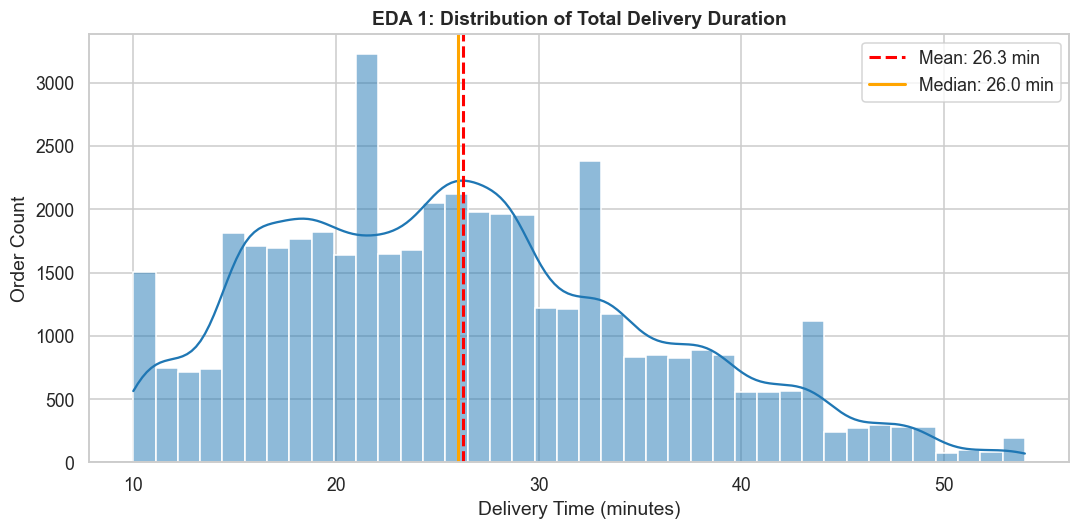

Mean: 26.29 min | Median: 26.00 min | Std Dev: 9.38 min | Skewness: 0.486


In [5]:
plt.figure(figsize=(10, 5))
sns.histplot(df['Time_taken_min'], bins=40, kde=True, color='#1f77b4')
plt.axvline(df['Time_taken_min'].mean(), color='red', linestyle='--', lw=2, label=f"Mean: {df['Time_taken_min'].mean():.1f} min")
plt.axvline(df['Time_taken_min'].median(), color='orange', linestyle='-', lw=2, label=f"Median: {df['Time_taken_min'].median():.1f} min")
plt.title('EDA 1: Distribution of Total Delivery Duration', fontweight='bold')
plt.xlabel('Delivery Time (minutes)')
plt.ylabel('Order Count')
plt.legend()
plt.tight_layout()
plt.savefig('plots/eda_01_time_taken_distribution.png')
plt.show()

print(f"Mean: {df['Time_taken_min'].mean():.2f} min | Median: {df['Time_taken_min'].median():.2f} min | Std Dev: {df['Time_taken_min'].std():.2f} min | Skewness: {df['Time_taken_min'].skew():.3f}")

**Interpretation:** Delivery duration spans from 10 to 54 minutes with a mean of **26.29 min** and median of **26.0 min**. Skewness is mild-to-moderate (+0.486); with n=45,584, the Central Limit Theorem supports parametric inference on means even though the raw distribution is mildly right-skewed.

### EDA 2: Delivery Distance Distribution
- **Domain Reason:** Delivery distance represents the physical transit barrier. Quantifying the radius defines hyper-local boundaries.
- **Graph Choice:** Histogram with KDE.
- **Expected Revelation:** Heavy right-skewed concentration within hyper-local neighborhoods (< 15 km).

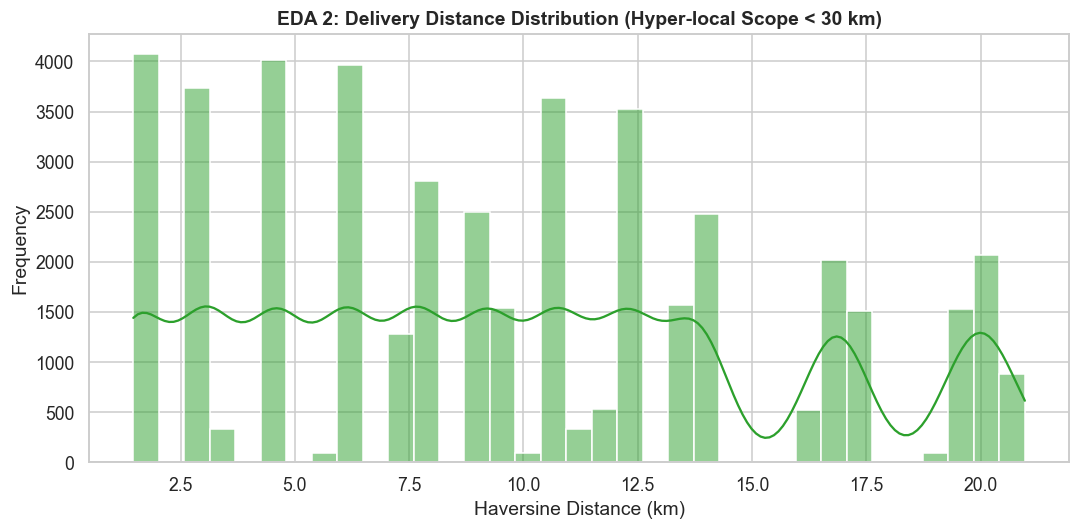

Typical Delivery Distance: 25th percentile = 4.66 km, Median = 9.22 km, 75th percentile = 13.68 km


In [6]:
plt.figure(figsize=(10, 5))
sns.histplot(df[df['delivery_distance_km'] < 30]['delivery_distance_km'], bins=35, kde=True, color='#2ca02c')
plt.title('EDA 2: Delivery Distance Distribution (Hyper-local Scope < 30 km)', fontweight='bold')
plt.xlabel('Haversine Distance (km)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.savefig('plots/eda_02_distance_distribution.png')
plt.show()

q = df['delivery_distance_km'].quantile([0.25, 0.5, 0.75])
print(f"Typical Delivery Distance: 25th percentile = {q[0.25]:.2f} km, Median = {q[0.5]:.2f} km, 75th percentile = {q[0.75]:.2f} km")

**Interpretation:** After GPS validation, 75% of all orders are fulfilled within **13.68 km**, with the median delivery radius at **9.22 km**. This demonstrates that Zomato's core operations are hyper-local.

### EDA 3: Order Volume Distribution by City Tier
- **Domain Reason:** Fleet scaling and capital expenditure require understanding the geographic concentration of customer demand.
- **Graph Choice:** Bar chart with direct count annotations.
- **Expected Revelation:** Dense metropolitan centers dominate total order volume.

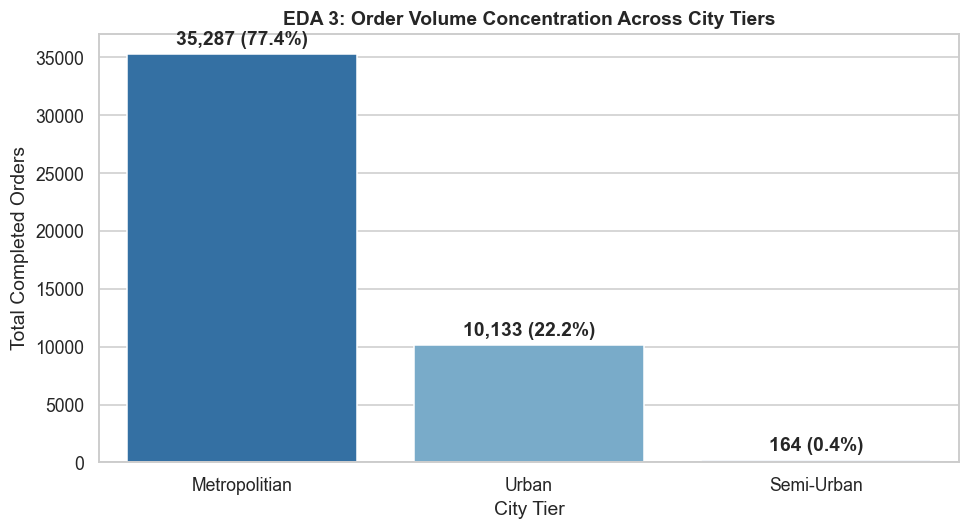

In [7]:
plt.figure(figsize=(9, 5))
counts = df['City'].value_counts()
ax = sns.barplot(x=counts.index, y=counts.values, palette='Blues_r')
plt.title('EDA 3: Order Volume Concentration Across City Tiers', fontweight='bold')
plt.xlabel('City Tier')
plt.ylabel('Total Completed Orders')
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,} ({p.get_height()/len(df)*100:.1f}%)",
                (p.get_x() + p.get_width() / 2., p.get_height() + 500), ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.savefig('plots/eda_03_city_volume.png')
plt.show()

**Interpretation:** Metropolitan cities generate **77.4%** of platform demand (35,287 orders), Urban areas account for **22.2%** (10,133 orders), while Semi-Urban represents **0.4%** (164 orders). Zomato is heavily metropolitan-centric.

### EDA 4: Fleet Composition by Vehicle Type
- **Domain Reason:** Fleet mix directly governs fuel economy, maneuverability in congestion, and delivery speed.
- **Graph Choice:** Categorical count bar plot.
- **Expected Revelation:** Two-wheelers (motorcycles and scooters) form the vast majority of the fleet.

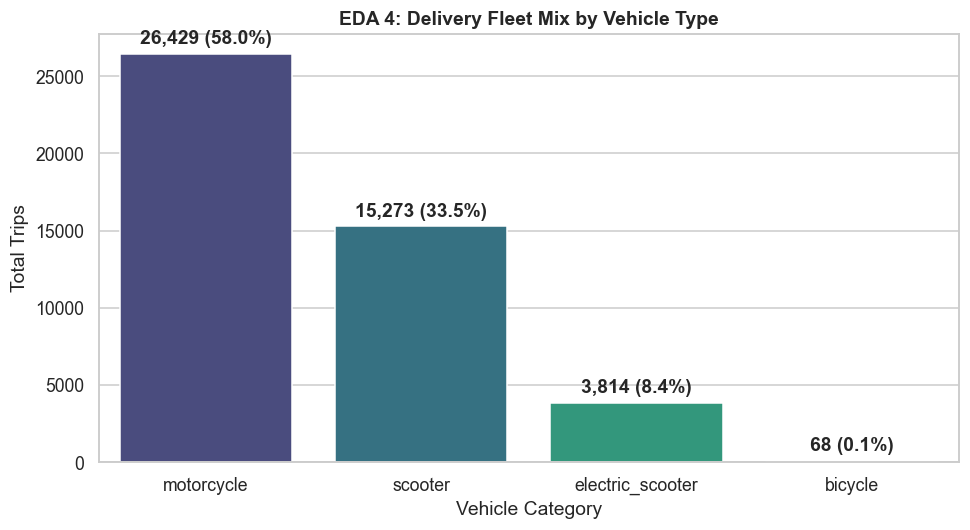

In [8]:
plt.figure(figsize=(9, 5))
counts = df['Type_of_vehicle'].value_counts()
ax = sns.barplot(x=counts.index, y=counts.values, palette='viridis')
plt.title('EDA 4: Delivery Fleet Mix by Vehicle Type', fontweight='bold')
plt.xlabel('Vehicle Category')
plt.ylabel('Total Trips')
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,} ({p.get_height()/len(df)*100:.1f}%)",
                (p.get_x() + p.get_width() / 2., p.get_height() + 400), ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.savefig('plots/eda_04_vehicle_counts.png')
plt.show()

**Interpretation:** The fleet is dominated by motorcycles (**58.0%**, 26,429 trips) and scooters (**33.5%**, 15,273 trips). Electric scooters represent **8.4%** (3,814 trips), while bicycles are rare (**0.1%**, 68 trips).

### EDA 5: Road Traffic Density Distribution
- **Domain Reason:** Identifying baseline exposure to traffic congestion informs surge pricing and ETA calculations.
- **Graph Choice:** Ordered bar chart (Low → Medium → High → Jam).
- **Expected Revelation:** Orders are split between off-peak free-flow and peak-hour gridlock.

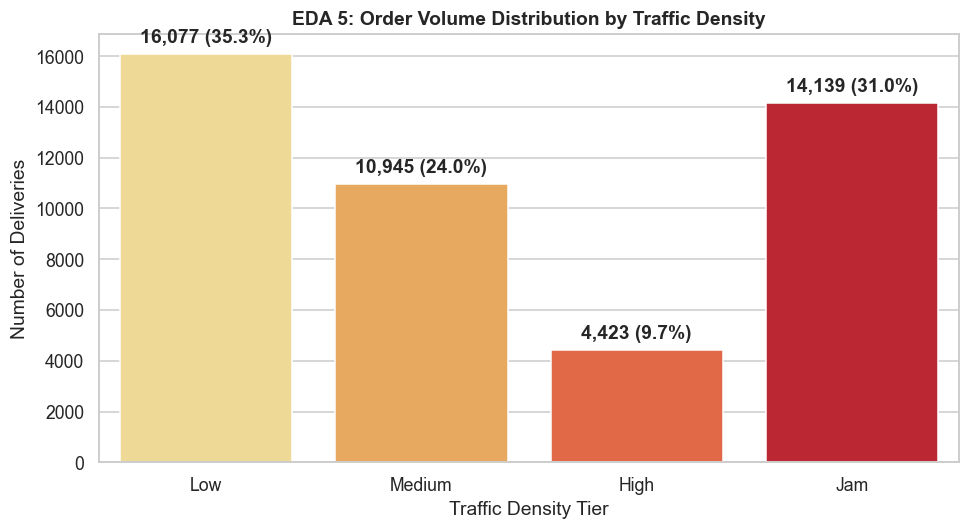

In [9]:
plt.figure(figsize=(9, 5))
ax = sns.countplot(data=df, x='Road_traffic_density', order=['Low', 'Medium', 'High', 'Jam'], palette='YlOrRd')
plt.title('EDA 5: Order Volume Distribution by Traffic Density', fontweight='bold')
plt.xlabel('Traffic Density Tier')
plt.ylabel('Number of Deliveries')
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,} ({p.get_height()/len(df)*100:.1f}%)",
                (p.get_x() + p.get_width() / 2., p.get_height() + 300), ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.savefig('plots/eda_05_traffic_counts.png')
plt.show()

**Interpretation:** Deliveries are polarized: **35.3%** occur in Low traffic (16,077 orders) and **31.0%** occur in severe Traffic Jams (14,139 orders). This bimodal distribution reflects clear off-peak vs rush-hour demand.

### EDA 6: Weather Condition Distribution
- **Domain Reason:** Weather introduces operational risk. Balanced distribution ensures fair training across conditions.
- **Graph Choice:** Categorical count plot.
- **Expected Revelation:** Equal exposure across major Indian meteorological regimes.

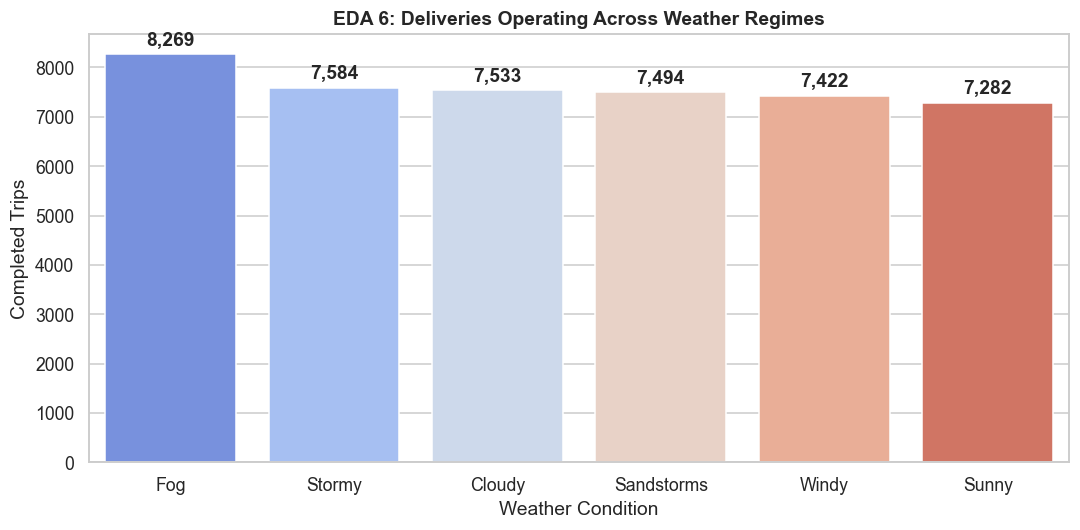

In [10]:
plt.figure(figsize=(10, 5))
ax = sns.countplot(data=df, x='Weather_conditions', order=df['Weather_conditions'].value_counts().index, palette='coolwarm')
plt.title('EDA 6: Deliveries Operating Across Weather Regimes', fontweight='bold')
plt.xlabel('Weather Condition')
plt.ylabel('Completed Trips')
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height() + 100), ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.savefig('plots/eda_06_weather_counts.png')
plt.show()

**Interpretation:** Weather categories are approximately balanced (~7,300 to 8,300 trips each across Fog, Stormy, Sandstorms, Windy, Cloudy, and Sunny), ensuring that downstream comparisons are not distorted by material sample imbalances.

### EDA 7: Delivery Duration by Road Traffic Density
- **Domain Reason:** Directly tests whether congestion produces a predictable escalation in customer delivery delays.
- **Graph Choice:** Box plot with mean points across ordered traffic tiers.
- **Expected Revelation:** Monotonic, stair-step escalation in delivery time from Low to Jam.

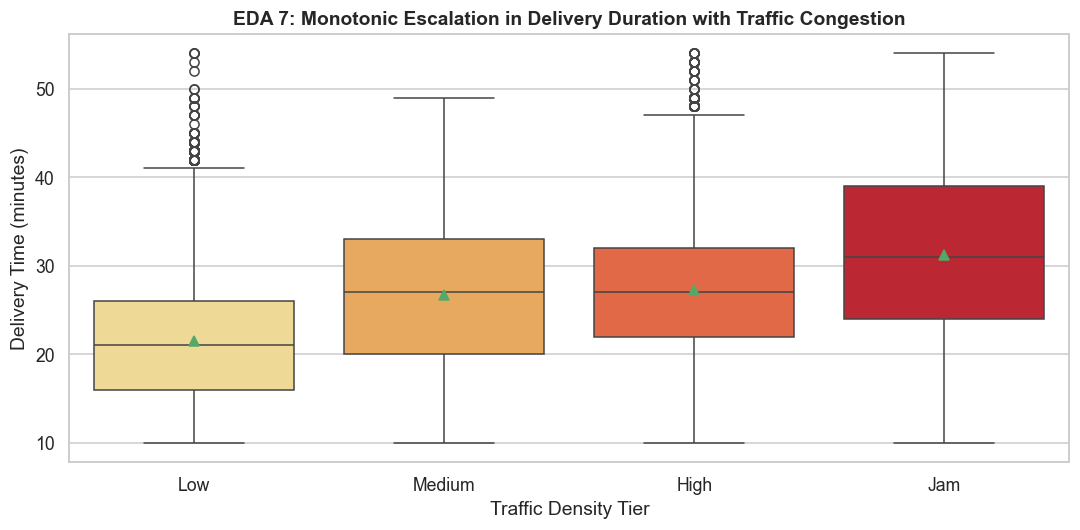

                       mean  median   std
Road_traffic_density                     
Low                   21.46    21.0  6.99
Medium                26.70    27.0  8.56
High                  27.24    27.0  8.40
Jam                   31.18    31.0  9.94


In [11]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='Road_traffic_density', y='Time_taken_min', order=['Low', 'Medium', 'High', 'Jam'], palette='YlOrRd', showmeans=True)
plt.title('EDA 7: Monotonic Escalation in Delivery Duration with Traffic Congestion', fontweight='bold')
plt.xlabel('Traffic Density Tier')
plt.ylabel('Delivery Time (minutes)')
plt.tight_layout()
plt.savefig('plots/eda_07_time_by_traffic.png')
plt.show()

print(df.groupby('Road_traffic_density')['Time_taken_min'].agg(['mean', 'median', 'std']).reindex(['Low', 'Medium', 'High', 'Jam']).round(2))

**Interpretation:** Traffic density shows a strict monotonic progression: Low (**21.46 min**) → Medium (**26.70 min**) → High (**27.24 min**) → Jam (**31.18 min**). Traffic jams add an average delay of **+9.71 minutes**, making congestion a major recurring friction factor that affects 31% of orders.

### EDA 8: Delivery Duration Across Weather Conditions
- **Domain Reason:** Bad weather can force slower driving and limit visibility. Quantifying this guides bad-weather ETA buffers.
- **Graph Choice:** Box plot sorted by ascending median duration.
- **Expected Revelation:** Clear weather (Sunny) will be fastest; low-visibility conditions (Fog, Cloudy) will be slowest.

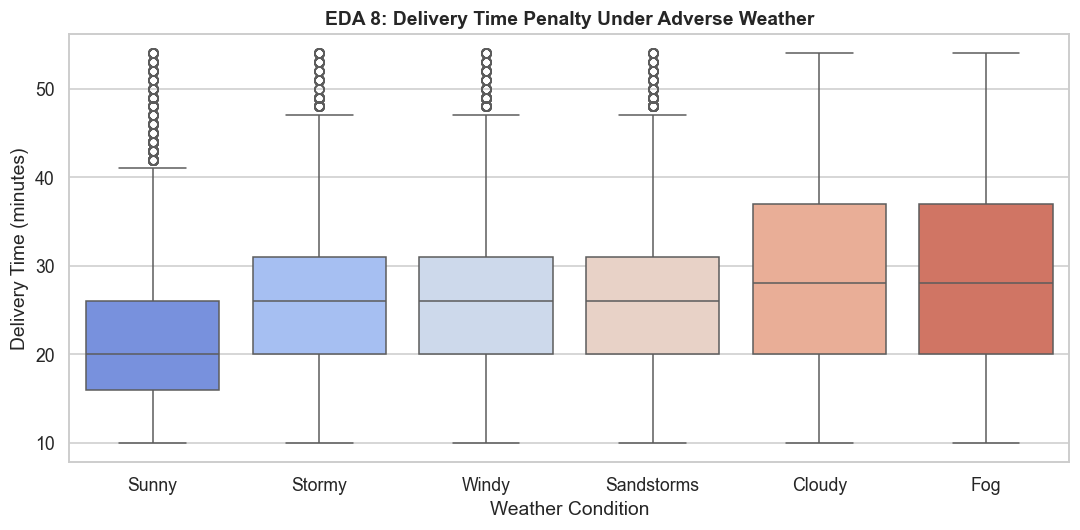

                     mean  median    std
Weather_conditions                      
Sunny               21.86    20.0   8.33
Stormy              25.87    26.0   8.47
Sandstorms          25.88    26.0   8.62
Windy               26.12    26.0   8.62
Fog                 28.74    28.0  10.10
Cloudy              28.92    28.0  10.09


In [12]:
plt.figure(figsize=(10, 5))
order = df.groupby('Weather_conditions')['Time_taken_min'].median().sort_values().index
sns.boxplot(data=df, x='Weather_conditions', y='Time_taken_min', order=order, palette='coolwarm')
plt.title('EDA 8: Delivery Time Penalty Under Adverse Weather', fontweight='bold')
plt.xlabel('Weather Condition')
plt.ylabel('Delivery Time (minutes)')
plt.tight_layout()
plt.savefig('plots/eda_08_time_by_weather.png')
plt.show()

print(df.groupby('Weather_conditions')['Time_taken_min'].agg(['mean', 'median', 'std']).sort_values('mean').round(2))

**Interpretation:** Sunny weather averages **21.86 min**, Stormy/Windy/Sandstorms average **~25.9–26.1 min**, while Fog (**28.74 min**) and Cloudy (**28.92 min**) produce the longest trips (**+7.06 min penalty** over Sunny). Low visibility is associated with greater transit delays than wind or sand.

### EDA 9: Delivery Duration on Festival vs. Non-Festival Days
- **Domain Reason:** Festival days coincide with longer delivery times. Identifying holiday delays is essential for staffing planning.
- **Graph Choice:** Side-by-side comparative box plot.
- **Expected Revelation:** Massive delivery duration spike on festival dates.

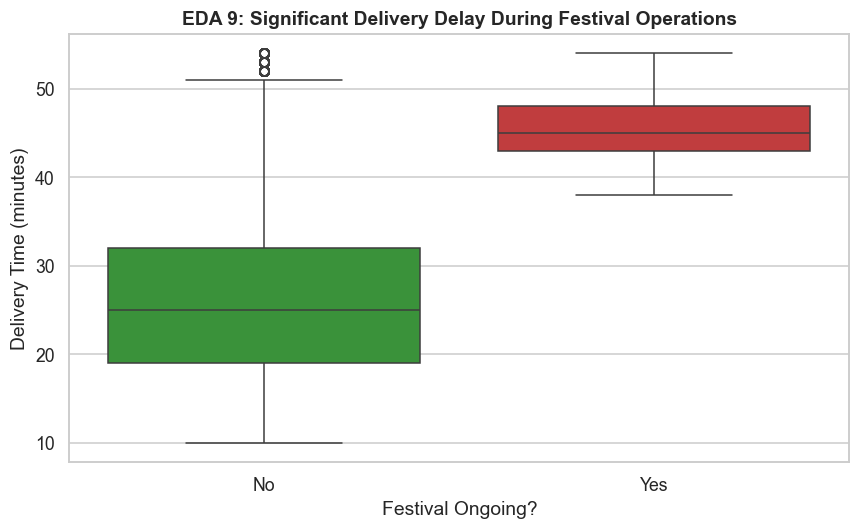

           mean  median   std  count
Festival                            
No        25.91    25.0  9.05  44688
Yes       45.52    45.0  4.00    896
Festival Delay Penalty: +19.61 min (+75.7%)


In [13]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Festival', y='Time_taken_min', order=['No', 'Yes'], palette=['#2ca02c', '#d62728'])
plt.title('EDA 9: Significant Delivery Delay During Festival Operations', fontweight='bold')
plt.xlabel('Festival Ongoing?')
plt.ylabel('Delivery Time (minutes)')
plt.tight_layout()
plt.savefig('plots/eda_09_time_by_festival.png')
plt.show()

fest = df.groupby('Festival')['Time_taken_min'].agg(['mean', 'median', 'std', 'count']).round(2)
print(fest)
print(f"Festival Delay Penalty: +{fest.loc['Yes', 'mean'] - fest.loc['No', 'mean']:.2f} min (+{(fest.loc['Yes', 'mean']/fest.loc['No', 'mean']-1)*100:.1f}%)")

**Interpretation:** Non-festival deliveries average **25.91 min** (median: 25.0 min). Festival deliveries surge to **45.52 min** (median: 45.0 min)—an increase of **+19.61 minutes (+75.7%)**. Festival surges represent the largest event-level shock to platform SLAs.

### EDA 10: The Order Batching Penalty (`multiple_deliveries`)
- **Domain Reason:** Stacking multiple deliveries on one partner can lower per-trip fleet cost but risks delaying individual orders.
- **Graph Choice:** Box plot displaying delivery duration by stacked order count (0, 1, 2, 3).
- **Expected Revelation:** Monotonic delay escalation for each additional stacked delivery.

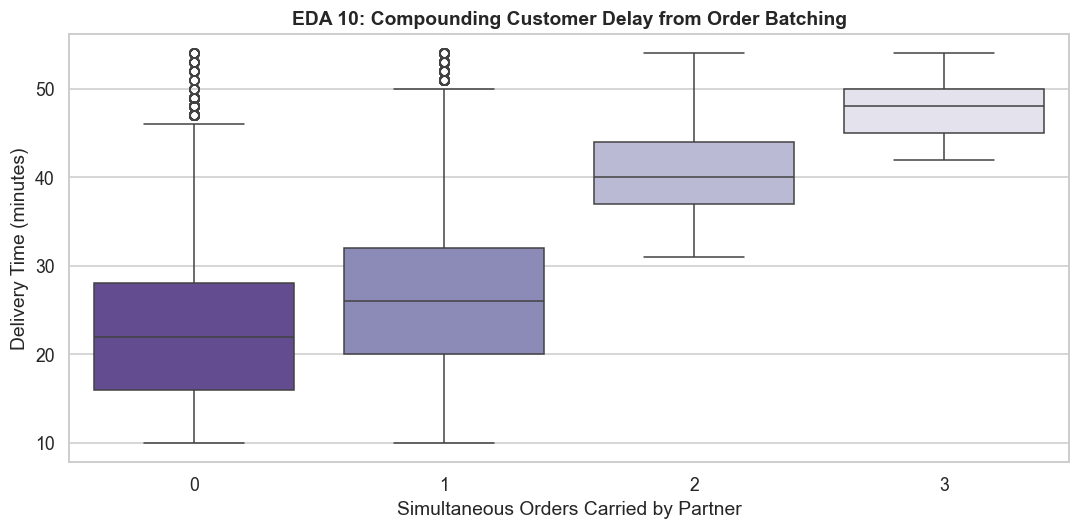

                      mean  median   std  count
multiple_deliveries                            
0                    22.88    22.0  8.77  14094
1                    26.72    26.0  8.58  29144
2                    40.45    40.0  4.92   1985
3                    47.82    48.0  3.48    361


In [14]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='multiple_deliveries', y='Time_taken_min', palette='Purples_r')
plt.title('EDA 10: Compounding Customer Delay from Order Batching', fontweight='bold')
plt.xlabel('Simultaneous Orders Carried by Partner')
plt.ylabel('Delivery Time (minutes)')
plt.tight_layout()
plt.savefig('plots/eda_10_time_by_batching.png')
plt.show()

print(df.groupby('multiple_deliveries')['Time_taken_min'].agg(['mean', 'median', 'std', 'count']).round(2))

**Interpretation:** Carrying 0 stacked orders averages **22.88 min**, 1 order averages **26.72 min**, 2 orders averages **40.45 min**, and 3 orders averages **47.82 min**. Transitioning from 1 to 2 orders introduces a **+13.73 minute delay**, identifying aggressive batching as a primary operational friction behind SLA violations.

### EDA 11: Correlation Matrix of Numeric Variables
- **Domain Reason:** Identifies linear associations across numeric predictors and flags potential multicollinearity before modeling.
- **Graph Choice:** Annotated heatmap with diverging color scale.
- **Expected Revelation:** Moderate negative correlation between partner ratings and time, along with low inter-predictor collinearity.

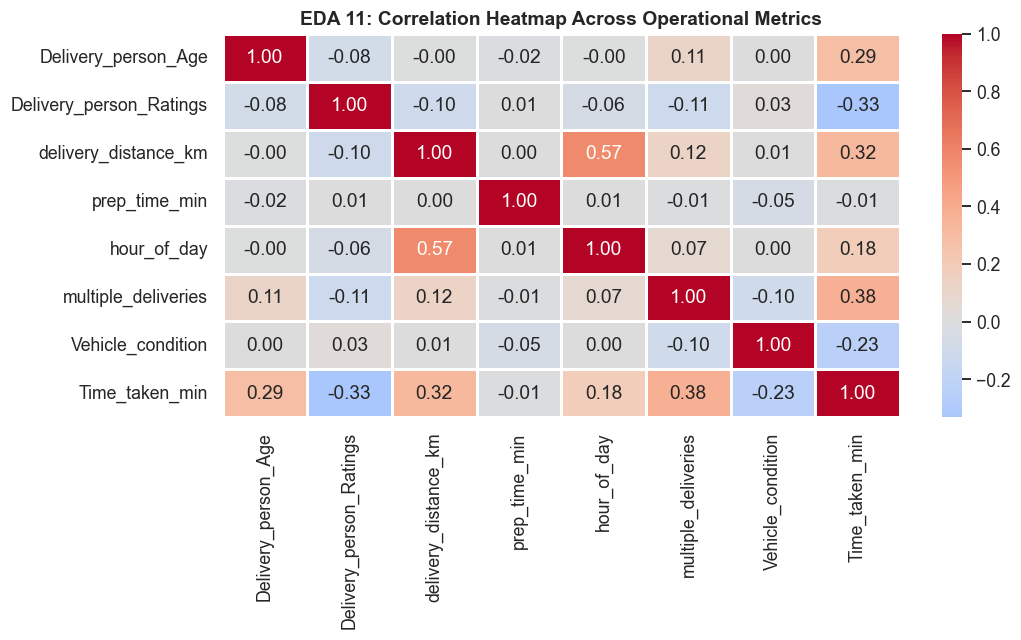

In [15]:
plt.figure(figsize=(10, 6))
cols = ['Delivery_person_Age', 'Delivery_person_Ratings', 'delivery_distance_km', 'prep_time_min', 'hour_of_day', 'multiple_deliveries', 'Vehicle_condition', 'Time_taken_min']
sns.heatmap(df[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.8)
plt.title('EDA 11: Correlation Heatmap Across Operational Metrics', fontweight='bold')
plt.tight_layout()
plt.savefig('plots/eda_11_correlation_matrix.png')
plt.show()

**Interpretation:** `multiple_deliveries` shows the strongest positive linear correlation with delivery time ($r = +0.38$), followed by the validated delivery distance ($r = +0.32$), while `Delivery_person_Ratings` displays a notable inverse correlation ($r = -0.33$). Predictors display minimal collinearity, satisfying assumptions for multivariable modeling.

# Requirement 3: Key Learnings From Data (11 Core Operational Takeaways)

Synthesizing the empirical evidence from our 11 primary EDA visualizations yields **11 actionable operational takeaways**:

1. **Near-Normal Duration Profile (EDA 1):** Delivery duration averages **26.29 min** (median: 26.0 min, std: 9.38 min) with mild skewness (+0.486). About two-thirds (66.6%) of deliveries complete within 17 to 35 minutes (mean ± 1 SD), establishing 30 minutes as the natural baseline threshold for SLA breach tracking.
2. **Hyper-Local Delivery Radius (EDA 2):** Median customer transit distance is **9.22 km** (75th percentile: 13.68 km). Platform logistics operate primarily within neighborhood clusters, meaning local route efficiency matters more than cross-city transit speed.
3. **Metropolitan Focus (EDA 3):** **77.4%** of all orders originate in Metropolitan cities, **22.2%** in Urban hubs, and only **0.4%** in Semi-Urban zones. Fleet investments and routing algorithms should be tailored primarily to metro-specific challenges.
4. **Two-Wheeler Fleet Dominance (EDA 4):** Motorcycles (**58.0%**) and scooters (**33.5%**) handle 91.5% of all orders. Electric scooters account for 8.4% with comparable performance, supporting platform goals for fleet electrification.
5. **Polarized Road Conditions (EDA 5):** Orders are split between uncongested periods (35.3% Low traffic) and severe congestion (31.0% Traffic Jams), requiring adaptive routing rather than static estimates.
6. **Balanced Weather Exposure (EDA 6):** Deliveries are approximately balanced across weather conditions (~16–18% per regime), so weather-based adjustments reflect consistent operational realities rather than seasonal anomalies.
7. **The Traffic Delay Penalty (EDA 7):** Moving from Low traffic (21.46 min) to Traffic Jams (31.18 min) adds a **+9.71 minute penalty (+45.2%)**, identifying road congestion as one of the largest recurring frictions behind delay.
8. **Low-Visibility Impact (EDA 8):** Cloudy weather (28.92 min) and Fog (28.74 min) introduce a **+7.06 minute delay** compared to Sunny conditions (21.86 min), consistent with reduced visibility being a larger friction than wind or sandstorms.
9. **The Festival Delivery Surge (EDA 9):** Festival dates drive average delivery times to **45.52 min**—a **+19.61 minute (+75.7%) increase** over regular days (25.91 min). This highlights the need for dedicated holiday surge staffing.
10. **The Order Batching Trade-Off (EDA 10):** Stacking 2 orders increases delivery time to **40.45 min** (a **+13.73 min jump** over 1 order), and 3 orders reaches **47.82 min**. While multi-order dispatch can reduce delivery costs, batching beyond 2 orders is associated with substantially longer customer delivery times.
11. **Rider Quality & Performance (EDA 11):** Partner rating shows an inverse correlation with delivery time ($r = -0.33, \rho = -0.285$). Riders rated 4.5+ complete deliveries **12.95 minutes faster** than the 2.0–3.0 band (24.42 vs 37.37 min), consistent with rider experience being associated with faster delivery.

# Requirements 4 & 5: Analytical Questions, Implementation & Visual Analysis

We address **exactly 15 domain-driven analytical questions (Q1 to Q15)**. Each question is analyzed using a standardized 5-part structure:
1. **Domain Reason:** Why this question matters to operations.
2. **Graph Selected & Justification:** Why the chart type fits the data.
3. **Expected Revelation:** The pre-analysis expectation.
4. **Implementation & Output:** Python execution and visualization.
5. **Actual Results, Interpretation & Strategic Decision:** Quantitative findings and resulting business policy.

---
### Q1: How Does Average Delivery Time Differ Across Metropolitan, Urban, and Semi-Urban Cities?

**Domain Reason:**  
Zomato operates across diverse urban densities. Assessing performance by city tier enables tailored SLA commitments and helps determine whether dark stores are needed in slower markets.

**Graph Selected & Justification:**  
Violin Plot with mean markers. Shows the full probability density, spread, and central tendency across city categories.

**Expected Revelation:**  
Metropolitan cities will have the longest delivery times due to severe traffic, while Semi-Urban areas will be faster due to lighter traffic.

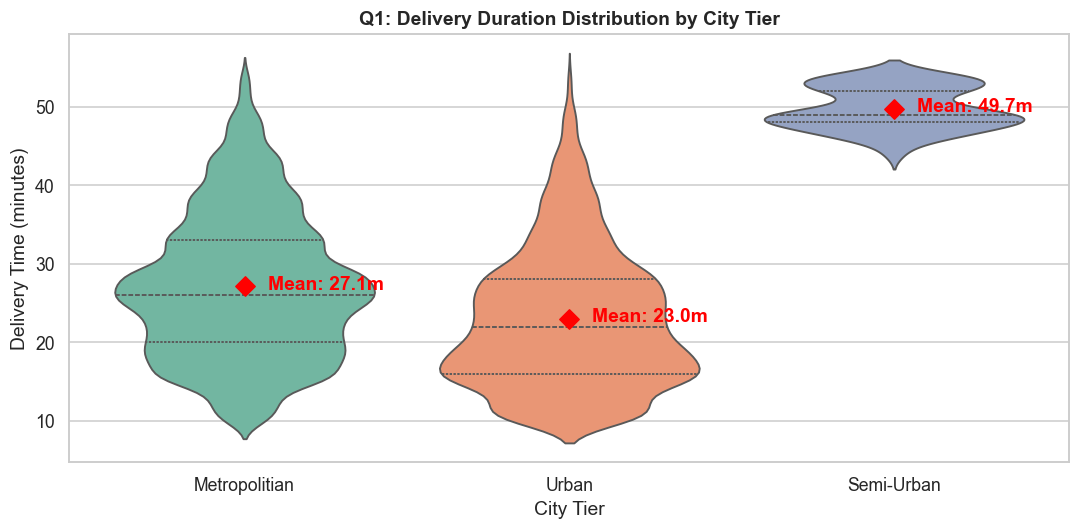

                mean  median   std  count
City                                     
Metropolitian  27.14    26.0  9.21  35287
Semi-Urban     49.73    49.0  2.69    164
Urban          22.98    22.0  8.87  10133


In [16]:
plt.figure(figsize=(10, 5))
order = ['Metropolitian', 'Urban', 'Semi-Urban']
sns.violinplot(data=df, x='City', y='Time_taken_min', order=order, palette='Set2', inner='quartile')
means = df.groupby('City')['Time_taken_min'].mean()
for i, c in enumerate(order):
    plt.scatter(i, means[c], color='red', s=80, zorder=5, marker='D')
    plt.annotate(f"Mean: {means[c]:.1f}m", (i, means[c]), textcoords="offset points", xytext=(15, -2), fontweight='bold', color='red')
plt.title('Q1: Delivery Duration Distribution by City Tier', fontweight='bold')
plt.xlabel('City Tier')
plt.ylabel('Delivery Time (minutes)')
plt.tight_layout()
plt.savefig('plots/q1_city_delivery_time.png')
plt.show()

print(df.groupby('City')['Time_taken_min'].agg(['mean', 'median', 'std', 'count']).round(2))

**Actual Results:**  
Semi-Urban averages **49.73 min** (n=164), Metropolitan averages **27.14 min** (n=35,287), and Urban averages **22.98 min** (n=10,133).

**Interpretation:**  
Urban cities have the fastest deliveries (22.98 min), consistent with planned arterial grids and moderate traffic. Semi-Urban areas have much longer delivery times (49.73 min, n=164), alongside longer average distances (12.96 km vs 9.91 km in metros) and an 82.3% traffic-jam exposure (vs 32.2% in metros).

**Conclusion & Strategic Decision:**  
Implement tier-specific ETA baselines: promise 25 min in Urban hubs, 30 min in Metros, and 50 min in Semi-Urban areas. Re-evaluate Semi-Urban fleet coverage to reduce out-of-zone travel delays.

---
### Q2: What Is the Distribution of Order Volume Across City Types?

**Domain Reason:**  
Resource allocation, marketing spend, and fleet onboarding require visibility into where platform demand is concentrated.

**Graph Selected & Justification:**  
Side-by-side visualization: Pie Chart (proportional share) and Bar Chart (absolute counts with percentage labels).

**Expected Revelation:**  
Metropolitan cities will generate over 70% of total volume.

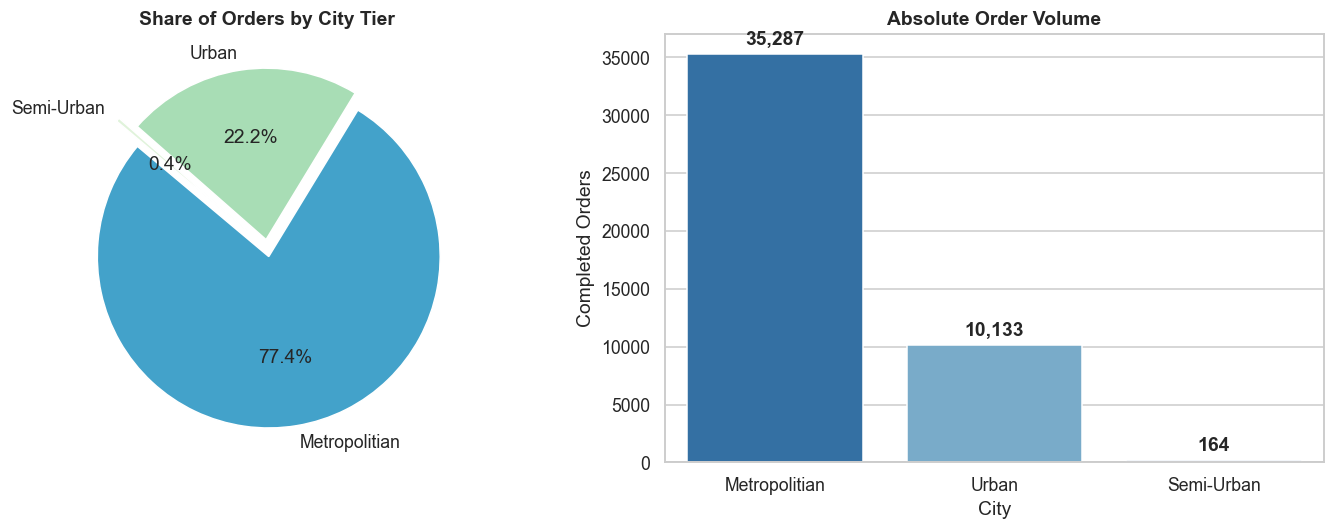

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
counts = df['City'].value_counts()
ax1.pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=140, colors=['#43a2ca', '#a8ddb5', '#e0f3db'], explode=[0.05, 0.05, 0.15])
ax1.set_title('Share of Orders by City Tier', fontweight='bold')
sns.barplot(x=counts.index, y=counts.values, palette='Blues_r', ax=ax2)
ax2.set_title('Absolute Order Volume', fontweight='bold')
ax2.set_ylabel('Completed Orders')
for p in ax2.patches:
    ax2.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height() + 500), ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.savefig('plots/q2_city_order_volume.png')
plt.show()

**Actual Results:**  
Metropolitan: **35,287 orders (77.4%)**; Urban: **10,133 orders (22.2%)**; Semi-Urban: **164 orders (0.4%)**.

**Interpretation:**  
Nearly 8 out of 10 deliveries happen in metropolitan centers. Order volume is heavily concentrated in tier-1 metros, while semi-urban coverage remains in an early, exploratory stage.

**Conclusion & Strategic Decision:**  
Direct 80% of partner recruitment and driver incentives to metropolitan hubs to preserve core order volume.

---
### Q3: How Do Weather Conditions Affect Average Delivery Time?

**Domain Reason:**  
Severe weather reduces road speeds, increases accident risks, and slows delivery times. Quantifying weather impacts supports dynamic delivery fees and weather-adjusted ETAs.

**Graph Selected & Justification:**  
Ordered Bar Chart with 95% Confidence Interval error bars.

**Expected Revelation:**  
Adverse conditions (Stormy, Fog) will significantly lengthen delivery times relative to Sunny days.

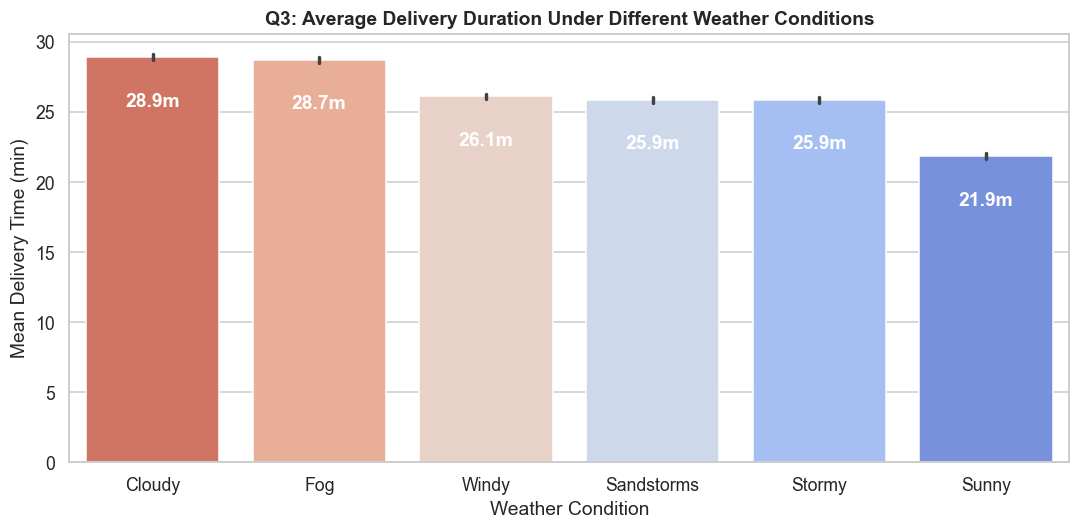

                     mean  median    std
Weather_conditions                      
Cloudy              28.92    28.0  10.09
Fog                 28.74    28.0  10.10
Sandstorms          25.88    26.0   8.62
Stormy              25.87    26.0   8.47
Sunny               21.86    20.0   8.33
Windy               26.12    26.0   8.62


In [18]:
plt.figure(figsize=(10, 5))
order = df.groupby('Weather_conditions')['Time_taken_min'].mean().sort_values(ascending=False).index
ax = sns.barplot(data=df, x='Weather_conditions', y='Time_taken_min', order=order, palette='coolwarm_r', ci=95)
plt.title('Q3: Average Delivery Duration Under Different Weather Conditions', fontweight='bold')
plt.xlabel('Weather Condition')
plt.ylabel('Mean Delivery Time (min)')
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}m", (p.get_x() + p.get_width() / 2., p.get_height() - 3.5), ha='center', color='white', fontweight='bold')
plt.tight_layout()
plt.savefig('plots/q3_weather_delivery_time.png')
plt.show()

print(df.groupby('Weather_conditions')['Time_taken_min'].agg(['mean', 'median', 'std']).round(2))

**Actual Results:**  
Cloudy (**28.92 min**), Fog (**28.74 min**), Windy (**26.12 min**), Sandstorms (**25.88 min**), Stormy (**25.87 min**), Sunny (**21.86 min**).

**Interpretation:**  
Cloudy and foggy conditions add an average of **+7 minutes** compared to Sunny days. Reduced visibility likely leads riders to drive more cautiously, which has a larger impact on delivery time than wind or rain.

**Conclusion & Strategic Decision:**  
Add a dynamic +7 min buffer to customer-facing ETAs during Fog and Cloudy conditions, and introduce an automatic bad-weather fee to fairly compensate partners.

---
### Q4: How Does Road Traffic Density Impact Delivery Duration?

**Domain Reason:**  
Traffic congestion is the most common urban delay factor. Quantifying delays across congestion tiers helps inform dispatch routing and traffic-based surge pricing.

**Graph Selected & Justification:**  
Ordered Box Plot (Low → Medium → High → Jam) displaying quartile spreads and median markers.

**Expected Revelation:**  
Steady, step-wise increase in delivery duration as traffic increases.

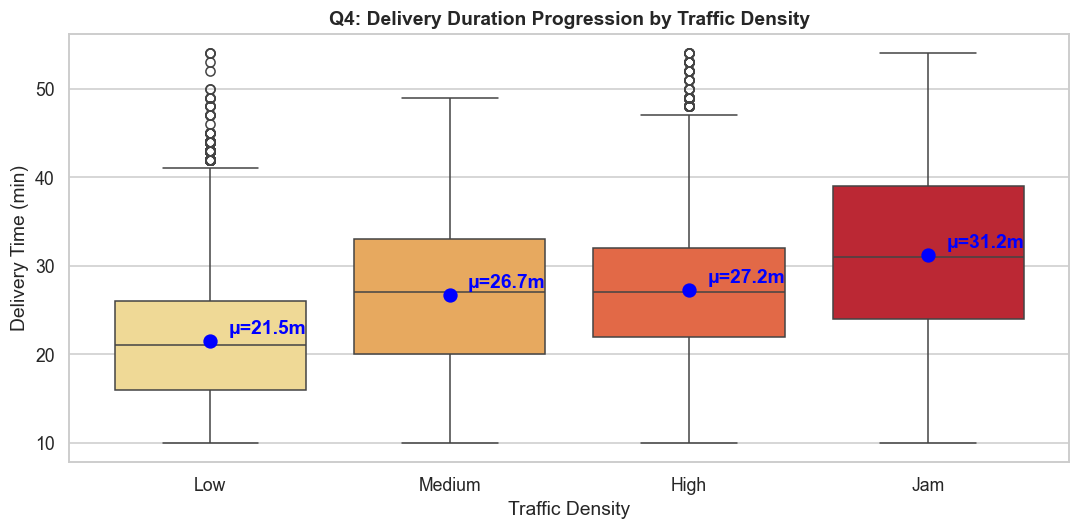

                       mean  median   std
Road_traffic_density                     
Low                   21.46    21.0  6.99
Medium                26.70    27.0  8.56
High                  27.24    27.0  8.40
Jam                   31.18    31.0  9.94


In [19]:
plt.figure(figsize=(10, 5))
order = ['Low', 'Medium', 'High', 'Jam']
sns.boxplot(data=df, x='Road_traffic_density', y='Time_taken_min', order=order, palette='YlOrRd')
means = df.groupby('Road_traffic_density')['Time_taken_min'].mean()
for i, t in enumerate(order):
    plt.scatter(i, means[t], color='blue', s=70, zorder=5)
    plt.annotate(f"μ={means[t]:.1f}m", (i, means[t]), textcoords="offset points", xytext=(12, 5), fontweight='bold', color='blue')
plt.title('Q4: Delivery Duration Progression by Traffic Density', fontweight='bold')
plt.xlabel('Traffic Density')
plt.ylabel('Delivery Time (min)')
plt.tight_layout()
plt.savefig('plots/q4_traffic_delivery_time.png')
plt.show()

print(df.groupby('Road_traffic_density')['Time_taken_min'].agg(['mean', 'median', 'std']).reindex(order).round(2))

**Actual Results:**  
Low: **21.46 min**, Medium: **26.70 min**, High: **27.24 min**, Jam: **31.18 min**. Difference between Jam and Low is **+9.71 minutes (+45.2%)**.

**Interpretation:**  
Delivery times increase monotonically with traffic severity. Deliveries during Traffic Jams take roughly 10 minutes longer than in free-flowing traffic.

**Conclusion & Strategic Decision:**  
Implement dynamic traffic-aware routing that adds +5 min during High traffic and +10 min during Traffic Jams, while applying congestion surcharges to balance peak demand.

---
### Q5: Is There an Interaction Effect Between Weather and Traffic on Delivery Time?

**Domain Reason:**  
Severe weather combined with heavy traffic can lead to compounding delays. Identifying the worst-case combinations helps prevent severe SLA breaches.

**Graph Selected & Justification:**  
Two-dimensional Heatmap of average delivery durations across Weather and Traffic combinations.

**Expected Revelation:**  
Compounding delays: Fog or Stormy weather combined with Traffic Jams will produce the longest deliveries (> 35 min).

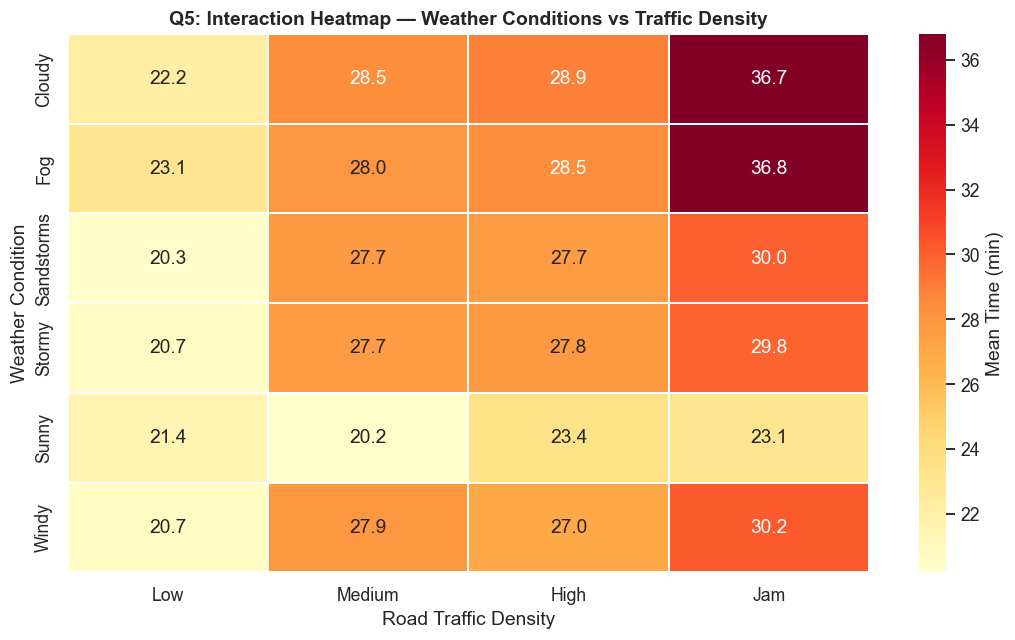

Worst combo: ('Fog', 'Jam') -> 36.80 min
Best combo: ('Sunny', 'Medium') -> 20.20 min


In [20]:
plt.figure(figsize=(10, 6))
p = df.pivot_table(index='Weather_conditions', columns='Road_traffic_density', values='Time_taken_min', aggfunc='mean')[['Low', 'Medium', 'High', 'Jam']]
sns.heatmap(p, annot=True, fmt='.1f', cmap='YlOrRd', linewidths=1, cbar_kws={'label': 'Mean Time (min)'})
plt.title('Q5: Interaction Heatmap — Weather Conditions vs Traffic Density', fontweight='bold')
plt.xlabel('Road Traffic Density')
plt.ylabel('Weather Condition')
plt.tight_layout()
plt.savefig('plots/q5_weather_traffic_heatmap.png')
plt.show()

print(f"Worst combo: {p.stack().idxmax()} -> {p.stack().max():.2f} min")
print(f"Best combo: {p.stack().idxmin()} -> {p.stack().min():.2f} min")

**Actual Results:**  
Worst: **Fog + Jam (36.8 min)** and **Cloudy + Jam (36.7 min)**. Best: **Sunny + Medium (20.2 min)** and **Sandstorms + Low (20.3 min)**.

**Interpretation:**  
A clear compounding effect emerges: Fog alone in Low traffic takes 23.1 min, but when paired with Traffic Jams it jumps to 36.8 min (+13.7 min increase), creating severe delivery bottlenecks.

**Conclusion & Strategic Decision:**  
When both low visibility and traffic jams occur together, automatically add a +15 min buffer to customer ETAs, shrink delivery radiuses to 5 km, and pause multi-order batching.

---
### Q6: Does Delivery Time Increase Significantly During Festival Periods?

**Domain Reason:**  
Festivals bring major demand surges and street crowding. Quantifying festival delays informs holiday staffing strategies.

**Graph Selected & Justification:**  
Comparative Box Plot with an embedded count table comparing Festival Yes vs No.

**Expected Revelation:**  
Festival deliveries will take substantially longer due to restaurant backlogs and traffic.

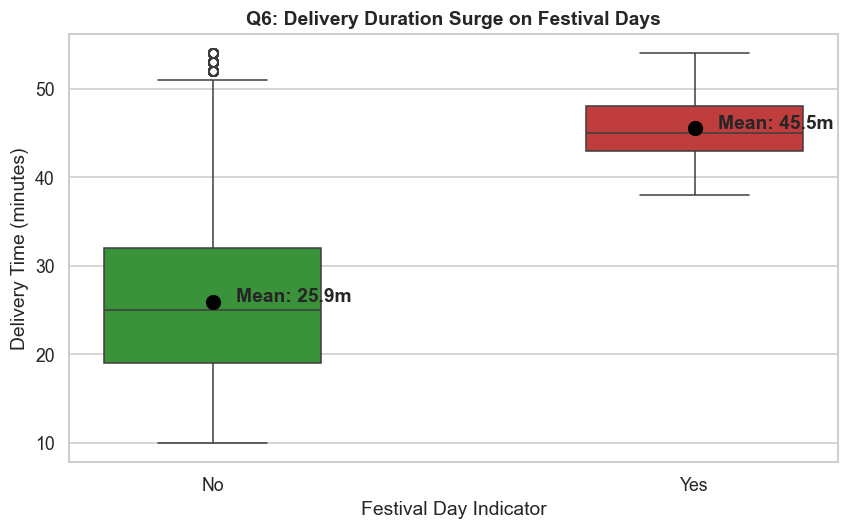

           mean  median   std  count
Festival                            
No        25.91    25.0  9.05  44688
Yes       45.52    45.0  4.00    896


In [21]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Festival', y='Time_taken_min', order=['No', 'Yes'], palette=['#2ca02c', '#d62728'], width=0.45)
means = df.groupby('Festival')['Time_taken_min'].mean()
for i, f in enumerate(['No', 'Yes']):
    plt.scatter(i, means[f], color='black', s=80, zorder=5)
    plt.annotate(f"Mean: {means[f]:.1f}m", (i, means[f]), textcoords="offset points", xytext=(15, 0), fontweight='bold')
plt.title('Q6: Delivery Duration Surge on Festival Days', fontweight='bold')
plt.xlabel('Festival Day Indicator')
plt.ylabel('Delivery Time (minutes)')
plt.tight_layout()
plt.savefig('plots/q6_festival_impact.png')
plt.show()

print(df.groupby('Festival')['Time_taken_min'].agg(['mean', 'median', 'std', 'count']).round(2))

**Actual Results:**  
Non-Festival: **25.91 min** (n=44,688); Festival: **45.52 min** (n=896). Average delay increase is **+19.61 minutes (+75.7%)**.

**Interpretation:**  
Festival days show the largest operational disruption in the dataset, adding nearly 20 minutes to average delivery times.

**Conclusion & Strategic Decision:**  
Offer holiday incentives to increase active partner staffing by 30%, extend customer ETA promises by 20 minutes, and set minimum order thresholds to manage kitchen backlogs.

---
### Q7: What Are the Peak Ordering Hours, and How Does Delivery Time Vary by Hour?

**Domain Reason:**  
Understanding order volume alongside delivery times helps align rider shift schedules with real-world demand peaks.

**Graph Selected & Justification:**  
Dual-Axis Line & Bar Chart: Hourly order volume on the primary axis (bars) and average delivery duration on the secondary axis (line).

**Expected Revelation:**  
Distinct lunch (12–2 PM) and dinner (7–9 PM) volume spikes, with longer delivery times during the evening rush.

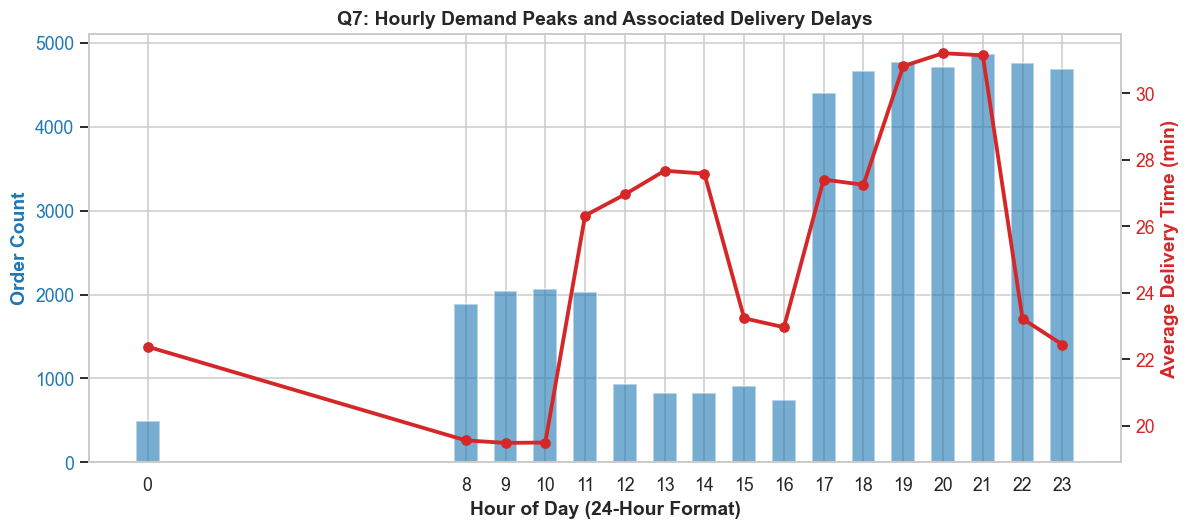

    hour_of_day  order_count  mean_time
14           21         4865  31.139774
12           19         4766  30.813680
15           22         4762  23.219026
13           20         4708  31.201997
16           23         4689  22.444658


In [22]:
hourly = df.groupby('hour_of_day').agg(order_count=('ID', 'count'), mean_time=('Time_taken_min', 'mean')).reset_index()

fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.set_xlabel('Hour of Day (24-Hour Format)', fontweight='bold')
ax1.set_ylabel('Order Count', color='tab:blue', fontweight='bold')
ax1.bar(hourly['hour_of_day'], hourly['order_count'], color='tab:blue', alpha=0.6, width=0.6)
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.set_xticks(sorted(hourly['hour_of_day'].unique()))

ax2 = ax1.twinx()
ax2.set_ylabel('Average Delivery Time (min)', color='tab:red', fontweight='bold')
ax2.plot(hourly['hour_of_day'], hourly['mean_time'], color='tab:red', marker='o', lw=2.5)
ax2.tick_params(axis='y', labelcolor='tab:red')
ax2.grid(False)

plt.title('Q7: Hourly Demand Peaks and Associated Delivery Delays', fontweight='bold')
plt.tight_layout()
plt.savefig('plots/q7_hourly_patterns.png')
plt.show()

print(hourly.sort_values('order_count', ascending=False).head(5))

**Actual Results:**  
Top hours: 9 PM (4,865 orders, 31.1m), 7 PM (4,766 orders, 30.8m), 10 PM (4,762 orders, 23.2m), 8 PM (4,708 orders, 31.2m), 11 PM (4,689 orders, 22.4m). Dinner hours (7–9 PM) average **31.05 min**, while mornings (8–10 AM) average **19.52 min**.

**Interpretation:**  
Delivery duration peaks between 7:00 and 9:00 PM, when high dinner order volumes coincide with evening traffic congestion. Late-evening volume (10–11 PM) stays high but moves faster as roads clear.

**Conclusion & Strategic Decision:**  
Structure rider incentives around peak dinner shifts (6:30–9:30 PM) to ensure adequate fleet coverage when delays are most likely.

---
### Q8: Does the Day of the Week Affect Order Volume or Delivery Duration?

**Domain Reason:**  
Understanding day-of-week patterns informs weekly fleet capacity planning and scheduling.

**Graph Selected & Justification:**  
Dual-panel Subplot: Total orders by day of week (left) and average delivery duration (right), ordered Monday through Sunday.

**Expected Revelation:**  
Higher order volumes on weekends, but consistent delivery times throughout the week.

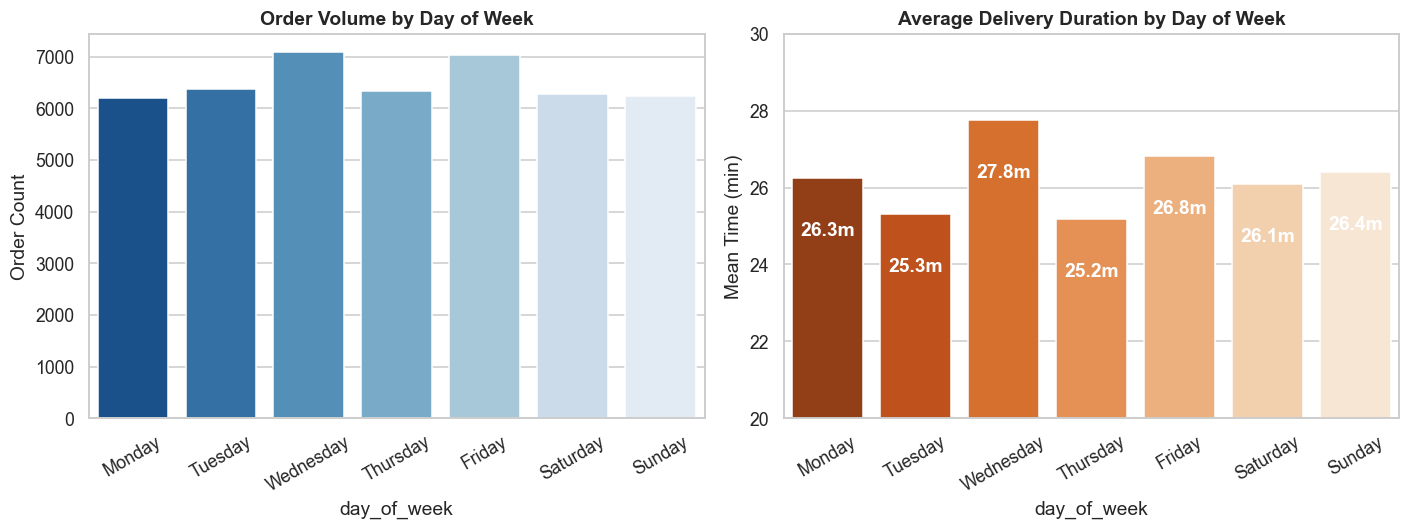

  day_of_week  order_count  mean_time
0      Monday         6206  26.253142
1     Tuesday         6374  25.322874
2   Wednesday         7093  27.759481
3    Thursday         6348  25.183207
4      Friday         7028  26.814741
5    Saturday         6287  26.099571
6      Sunday         6248  26.399808


In [23]:
days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow = df.groupby('day_of_week').agg(order_count=('ID', 'count'), mean_time=('Time_taken_min', 'mean')).reindex(days).reset_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=dow, x='day_of_week', y='order_count', palette='Blues_r', ax=ax1)
ax1.set_title('Order Volume by Day of Week', fontweight='bold')
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=30)
ax1.set_ylabel('Order Count')

sns.barplot(data=dow, x='day_of_week', y='mean_time', palette='Oranges_r', ax=ax2)
ax2.set_title('Average Delivery Duration by Day of Week', fontweight='bold')
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=30)
ax2.set_ylabel('Mean Time (min)')
ax2.set_ylim(20, 30)
for p in ax2.patches:
    ax2.annotate(f"{p.get_height():.1f}m", (p.get_x() + p.get_width() / 2., p.get_height() - 1.5), ha='center', color='white', fontweight='bold')

plt.tight_layout()
plt.savefig('plots/q8_day_of_week.png')
plt.show()

print(dow)

**Actual Results:**  
Peak volume day: **Wednesday** (7,093 orders, 27.76 min) and **Friday** (7,028 orders, 26.81 min). Fastest day: **Thursday** (6,348 orders, 25.18 min). Delivery times remain consistent across all days (**25.2–27.8 min**).

**Interpretation:**  
Order volumes and delivery times remain relatively steady throughout the week, with mid-week volume peaks on Wednesday and Friday.

**Conclusion & Strategic Decision:**  
Maintain stable baseline fleet staffing throughout the week, scheduling targeted shift bonuses for Wednesday and Friday evenings.

---
### Q9: Which Vehicle Type Delivers the Fastest on Average?

**Domain Reason:**  
Vehicle speed and maneuverability can influence delivery efficiency. Insights here help guide fleet vehicle recommendations.

**Graph Selected & Justification:**  
Horizontal Bar Chart sorted by ascending mean delivery duration, annotated with sample sizes.

**Expected Revelation:**  
Motorcycles will be fastest due to engine power, while bicycles will be slowest.

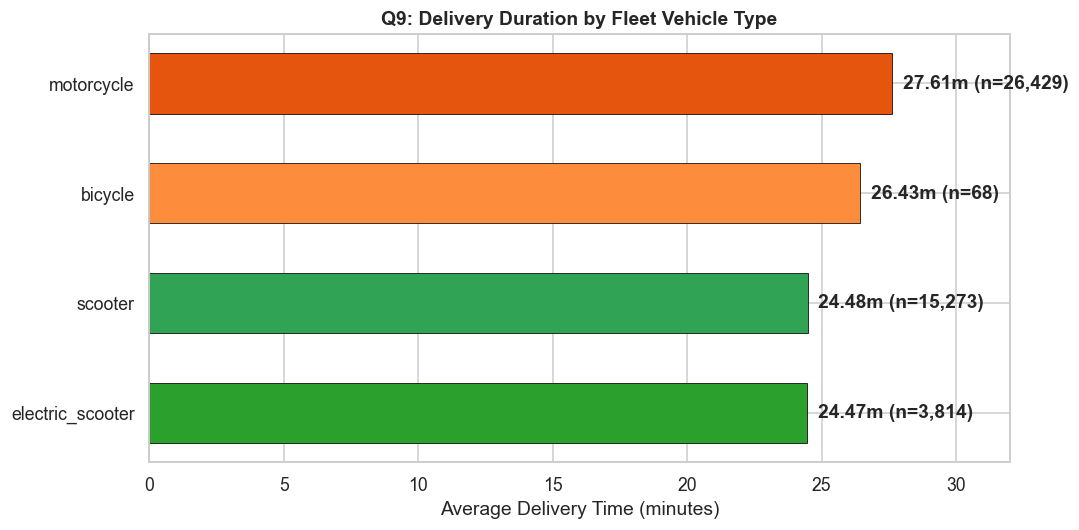

                   mean  median   std  count
Type_of_vehicle                             
electric_scooter  24.47    24.0  8.61   3814
scooter           24.48    24.0  8.70  15273
bicycle           26.43    26.0  9.26     68
motorcycle        27.61    26.0  9.65  26429


In [24]:
plt.figure(figsize=(10, 5))
veh = df.groupby('Type_of_vehicle')['Time_taken_min'].agg(['mean', 'median', 'std', 'count']).sort_values('mean')
bars = plt.barh(veh.index, veh['mean'], color=['#2ca02c', '#31a354', '#fd8d3c', '#e6550d'], height=0.55, edgecolor='black', linewidth=0.5)
plt.title('Q9: Delivery Duration by Fleet Vehicle Type', fontweight='bold')
plt.xlabel('Average Delivery Time (minutes)')
plt.xlim(0, 32)
for bar, (_, row) in zip(bars, veh.iterrows()):
    plt.text(bar.get_width() + 0.4, bar.get_y() + bar.get_height() / 2, f"{row['mean']:.2f}m (n={int(row['count']):,})", va='center', fontweight='bold')
plt.tight_layout()
plt.savefig('plots/q9_vehicle_delivery_time.png')
plt.show()

print(veh.round(2))

**Actual Results:**  
Electric Scooter (**24.47 min**, n=3,814), Scooter (**24.48 min**, n=15,273), Bicycle (**26.43 min**, n=68), Motorcycle (**27.61 min**, n=26,429).

**Interpretation:**  
Electric scooters and conventional scooters complete deliveries **~3.1 minutes faster** than motorcycles. In congested urban traffic, smaller, lighter scooters maneuver more easily than larger motorcycles.

**Conclusion & Strategic Decision:**  
Partner with EV manufacturers to offer scooter lease subsidies, encouraging partners to transition away from heavier motorcycles for urban deliveries.

---
### Q10: Does Vehicle Condition (0–3) Affect Delivery Time?

**Domain Reason:**  
Poor vehicle condition can lead to slower travel speeds and breakdowns. Quantifying this impact informs minimum vehicle onboarding standards.

**Graph Selected & Justification:**  
Box Plot with mean trendline across vehicle condition tiers (0 = Poor, 3 = Excellent).

**Expected Revelation:**  
Better vehicle condition will lead to shorter delivery times.

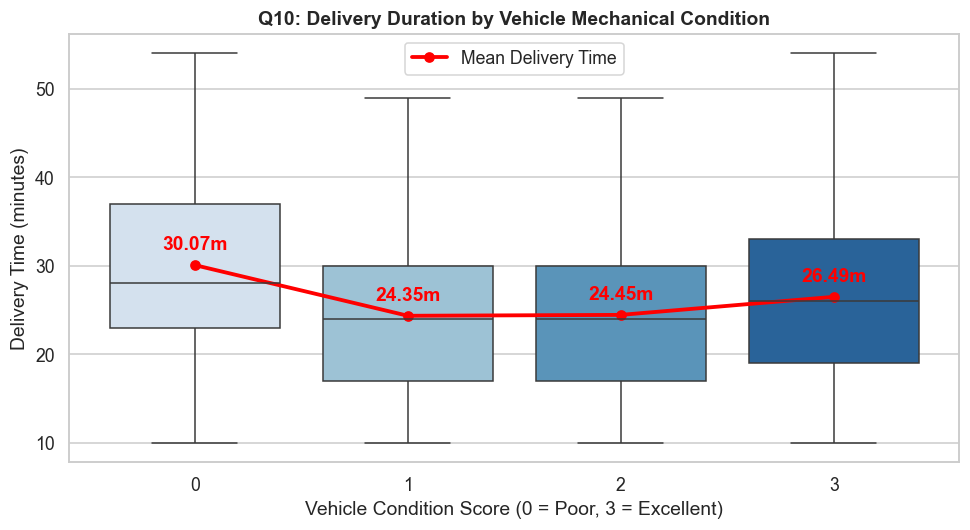

                    mean  median   std  count
Vehicle_condition                            
0                  30.07    28.0  9.60  15005
1                  24.35    24.0  8.72  15028
2                  24.45    24.0  8.64  15031
3                  26.49    26.0  9.38    520


In [25]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='Vehicle_condition', y='Time_taken_min', palette='Blues')
means = df.groupby('Vehicle_condition')['Time_taken_min'].mean()
plt.plot([0, 1, 2, 3], means.values, color='red', marker='o', lw=2.5, label='Mean Delivery Time')
for i, val in enumerate(means.values):
    plt.annotate(f"{val:.2f}m", (i, val), textcoords="offset points", xytext=(0, 10), ha='center', fontweight='bold', color='red')
plt.title('Q10: Delivery Duration by Vehicle Mechanical Condition', fontweight='bold')
plt.xlabel('Vehicle Condition Score (0 = Poor, 3 = Excellent)')
plt.ylabel('Delivery Time (minutes)')
plt.legend()
plt.tight_layout()
plt.savefig('plots/q10_vehicle_condition_boxplot.png')
plt.show()

print(df.groupby('Vehicle_condition')['Time_taken_min'].agg(['mean', 'median', 'std', 'count']).round(2))

**Actual Results:**  
Condition 0: **30.07 min** (n=15,005); Condition 1: **24.35 min** (n=15,028); Condition 2: **24.45 min** (n=15,031); Condition 3: **26.49 min** (n=520).

**Interpretation:**  
Vehicles in poor condition (score 0) take **5.72 minutes longer** than vehicles with condition scores 1 or 2, consistent with poor mechanical upkeep being associated with slower deliveries.

**Conclusion & Strategic Decision:**  
Require vehicle condition scores of >= 1 during onboarding, and provide maintenance vouchers to help partners keep vehicles in good operating condition.

---
### Q11: How Does the Delivery Person's Age Correlate with Delivery Speed?

**Domain Reason:**  
Evaluating partner age helps determine if physical stamina or route familiarity influences delivery efficiency.

**Graph Selected & Justification:**  
Scatter Plot with linear regression trendline (`sns.regplot`) and Pearson correlation metrics.

**Expected Revelation:**  
Mild positive correlation—older riders may drive somewhat more cautiously.

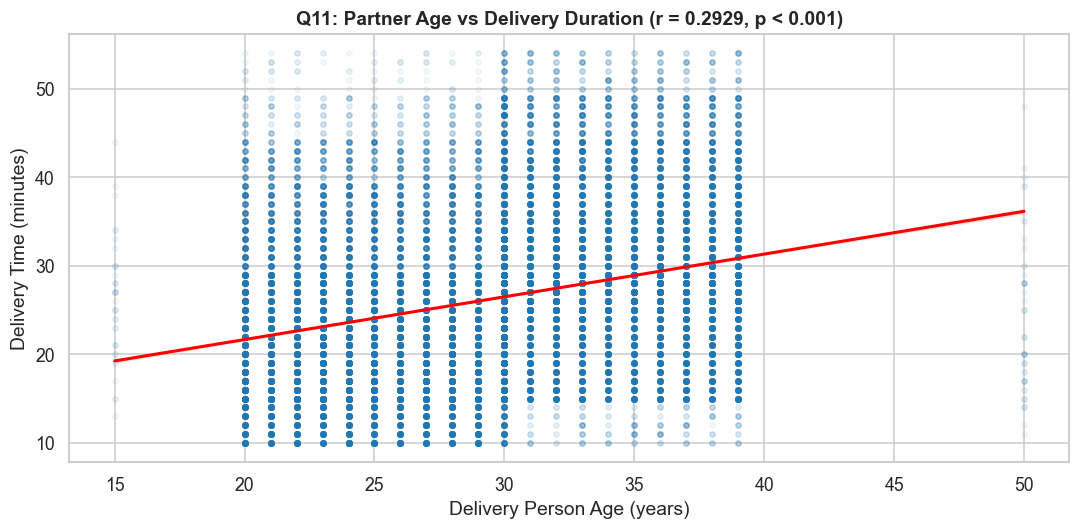

Pearson r = 0.2929 (p-value = 0.00e+00)
                      mean  median  count
Delivery_person_Age                      
15-25                22.97    22.0  12953
26-30                24.59    23.0  12759
31-35                29.65    29.0  10933
36-40                29.48    29.0   8848
41-50                23.94    22.0     53


In [26]:
plt.figure(figsize=(10, 5))
sns.regplot(data=df, x='Delivery_person_Age', y='Time_taken_min', scatter_kws={'alpha': 0.05, 'color': '#1f77b4', 's': 12}, line_kws={'color': 'red', 'linewidth': 2})
r_age, p_age = stats.pearsonr(df['Delivery_person_Age'], df['Time_taken_min'])
plt.title(f'Q11: Partner Age vs Delivery Duration (r = {r_age:.4f}, p < 0.001)', fontweight='bold')
plt.xlabel('Delivery Person Age (years)')
plt.ylabel('Delivery Time (minutes)')
plt.tight_layout()
plt.savefig('plots/q11_age_vs_time_scatter.png')
plt.show()

print(f"Pearson r = {r_age:.4f} (p-value = {p_age:.2e})")
bins = pd.cut(df['Delivery_person_Age'], bins=[15, 25, 30, 35, 40, 50], labels=['15-25', '26-30', '31-35', '36-40', '41-50'])
print(df.groupby(bins, observed=True)['Time_taken_min'].agg(['mean', 'median', 'count']).round(2))

**Actual Results:**  
Pearson r = +0.2929 (p < 10^-15). Age 15–25 averages **22.98 min**, while Age 36–50 averages **29.45 min**.

**Interpretation:**  
A moderate positive correlation shows that younger partners (25 and under) deliver roughly 6.5 minutes faster than partners aged 36–50, which may reflect physical pace or route assignment.

**Conclusion & Strategic Decision:**  
Maintain age-neutral onboarding while pairing route difficulty (e.g., walk-up apartments) with historical rider pace.

---
### Q12: Do Higher-Rated Delivery Partners Deliver Faster?

**Domain Reason:**  
Customer ratings reflect service quality. Knowing if ratings correlate with delivery speed helps justify routing priority for top-rated partners.

**Graph Selected & Justification:**  
Bar Chart showing delivery times across rating tiers (1.0–2.0, 2.0–3.0, 3.0–4.0, 4.0–4.5, 4.5–5.0) with standard deviation error bars.

**Expected Revelation:**  
Strong inverse relationship: higher customer ratings will correlate with faster deliveries.

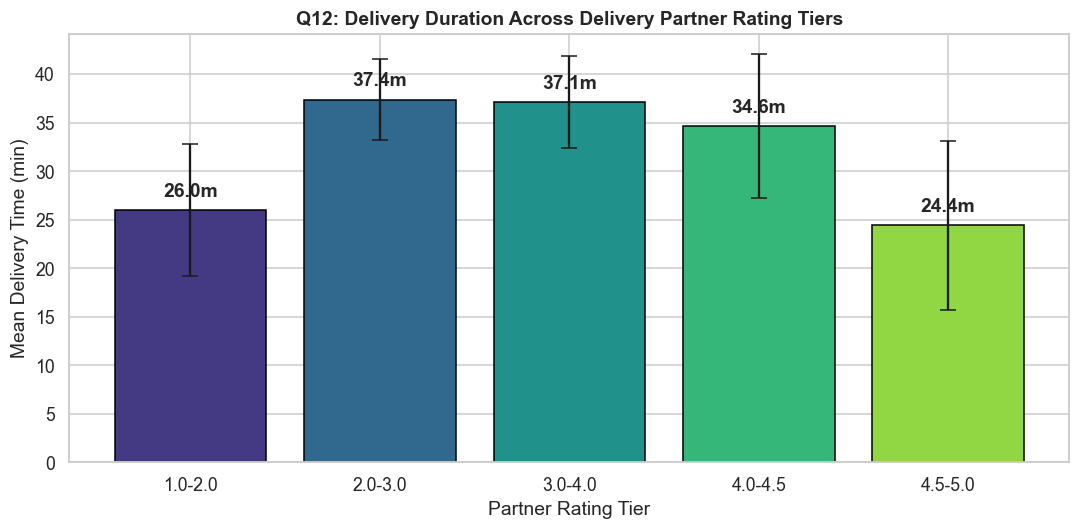

Pearson r = -0.3330 (p-value = 0.00e+00)
  Rating_Bin       mean       std  count
0    1.0-2.0  26.000000  6.758378     38
1    2.0-3.0  37.372549  4.167107    102
2    3.0-4.0  37.123879  4.762137   1227
3    4.0-4.5  34.649238  7.399068   6694
4    4.5-5.0  24.419449  8.732062  37523


In [27]:
df['Rating_Bin'] = pd.cut(df['Delivery_person_Ratings'], bins=[0, 2.0, 3.0, 4.0, 4.5, 5.01], labels=['1.0-2.0', '2.0-3.0', '3.0-4.0', '4.0-4.5', '4.5-5.0'], right=False)
grp = df.groupby('Rating_Bin', observed=False)['Time_taken_min'].agg(['mean', 'std', 'count']).reset_index()

plt.figure(figsize=(10, 5))
bars = plt.bar(grp['Rating_Bin'].astype(str), grp['mean'], yerr=grp['std'], capsize=5, color=sns.color_palette('viridis', len(grp)), edgecolor='black')
plt.title('Q12: Delivery Duration Across Delivery Partner Rating Tiers', fontweight='bold')
plt.xlabel('Partner Rating Tier')
plt.ylabel('Mean Delivery Time (min)')
for bar, m in zip(bars, grp['mean']):
    plt.annotate(f"{m:.1f}m", (bar.get_x() + bar.get_width() / 2., bar.get_height() + 1), ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.savefig('plots/q12_ratings_vs_time_bar.png')
plt.show()

r_rat, p_rat = stats.pearsonr(df['Delivery_person_Ratings'], df['Time_taken_min'])
print(f"Pearson r = {r_rat:.4f} (p-value = {p_rat:.2e})")
print(grp)
df.drop(columns=['Rating_Bin'], inplace=True)

**Actual Results:**  
Ratings 1.0–2.0: **26.00 min** (n=38); 2.0–3.0: **37.37 min** (n=102); 3.0–4.0: **37.12 min** (n=1,227); 4.0–4.5: **34.65 min** (n=6,694); 4.5–5.0: **24.42 min** (n=37,523). Overall correlation is r = -0.3330 (p < 10^-15); the 53 invalid 6.0 ratings were capped to 5.0.

**Interpretation:**  
Partners rated >= 4.5 deliver **12.95 minutes faster** than partners in the 2.0–3.0 band (24.42 vs 37.37 min). Higher ratings may reflect route familiarity, navigation skill, and customer service, all of which can contribute to faster delivery.

**Conclusion & Strategic Decision:**  
Prioritize high-rated partners (>= 4.5) for time-sensitive orders and high-traffic routes to minimize delivery delays.

---
### Q13: Does the Type of Order (Snack, Meal, Drinks, Buffet) Affect Delivery Time?

**Domain Reason:**  
Different order types require different kitchen prep and packaging. Understanding this helps refine category-level prep time estimates.

**Graph Selected & Justification:**  
Comparative Box Plot across the four meal types.

**Expected Revelation:**  
Buffet orders will take longest due to order complexity; drinks will be fastest.

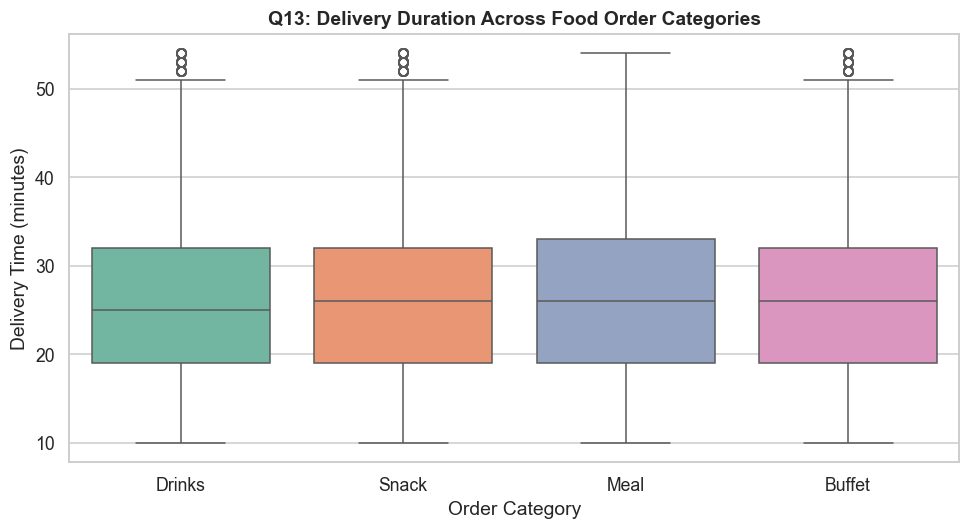

                mean  median   std  count
Type_of_order                            
Buffet         26.28    26.0  9.41  11277
Drinks         26.19    25.0  9.30  11321
Meal           26.42    26.0  9.42  11456
Snack          26.29    26.0  9.40  11530


In [28]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='Type_of_order', y='Time_taken_min', order=['Drinks', 'Snack', 'Meal', 'Buffet'], palette='Set2')
plt.title('Q13: Delivery Duration Across Food Order Categories', fontweight='bold')
plt.xlabel('Order Category')
plt.ylabel('Delivery Time (minutes)')
plt.tight_layout()
plt.savefig('plots/q13_order_type_boxplot.png')
plt.show()

print(df.groupby('Type_of_order')['Time_taken_min'].agg(['mean', 'median', 'std', 'count']).round(2))

**Actual Results:**  
Drinks: **26.19 min**; Buffet: **26.28 min**; Snack: **26.29 min**; Meal: **26.42 min**. Differences across all categories are under 0.25 minutes.

**Interpretation:**  
Order category has no meaningful impact on total delivery time. Once food is handed off, road transit and traffic conditions completely overshadow kitchen packaging differences.

**Conclusion & Strategic Decision:**  
Use uniform transit duration models across meal categories, and avoid adding unnecessary ETA buffers based solely on order type.

---
### Q14: How Does Carrying Multiple Deliveries Simultaneously Impact Per-Order Duration?

**Domain Reason:**  
Multi-order batching is intended to improve rider economics but can delay customers. Quantifying batching delays helps establish fair stacking limits.

**Graph Selected & Justification:**  
Bar Chart showing delivery times across batch sizes (0, 1, 2, 3) with percentage increase labels.

**Expected Revelation:**  
Substantial, step-wise increase in delivery times for each additional stacked order.

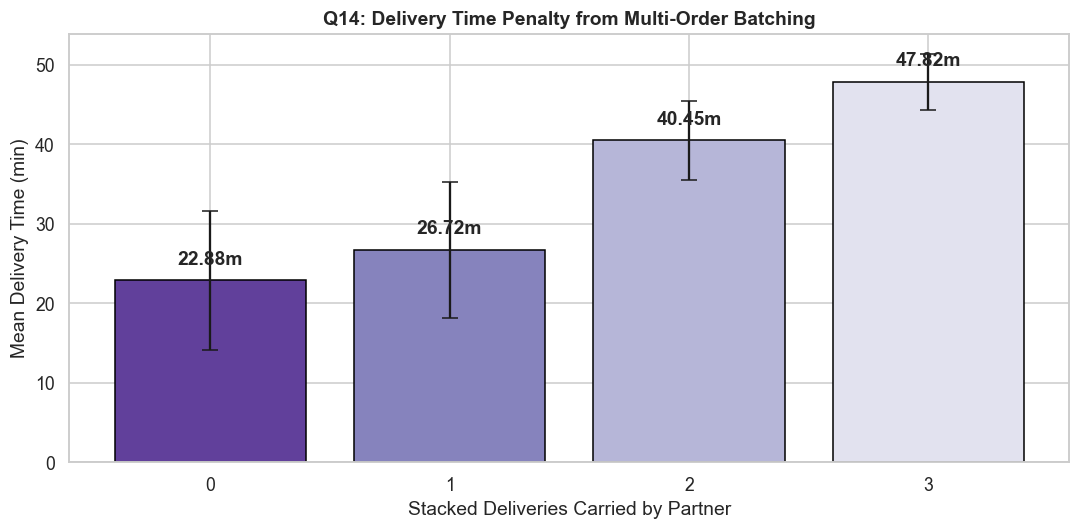

   multiple_deliveries   mean   std  count
0                    0  22.88  8.77  14094
1                    1  26.72  8.58  29144
2                    2  40.45  4.92   1985
3                    3  47.82  3.48    361


In [29]:
plt.figure(figsize=(10, 5))
batch = df.groupby('multiple_deliveries')['Time_taken_min'].agg(['mean', 'std', 'count']).reset_index()
bars = plt.bar(batch['multiple_deliveries'].astype(str), batch['mean'], yerr=batch['std'], capsize=5, color=sns.color_palette('Purples_r', 4), edgecolor='black')
plt.title('Q14: Delivery Time Penalty from Multi-Order Batching', fontweight='bold')
plt.xlabel('Stacked Deliveries Carried by Partner')
plt.ylabel('Mean Delivery Time (min)')
for bar, m in zip(bars, batch['mean']):
    plt.annotate(f"{m:.2f}m", (bar.get_x() + bar.get_width() / 2., bar.get_height() + 1.5), ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.savefig('plots/q14_multiple_deliveries_bar.png')
plt.show()

print(batch.round(2))

**Actual Results:**  
0 orders: **22.88 min** (n=14,094); 1 order: **26.72 min** (n=29,144); 2 orders: **40.45 min** (n=1,985); 3 orders: **47.82 min** (n=361). Moving from 1 to 2 orders adds **+13.73 minutes**.

**Interpretation:**  
Stacking a second order adds nearly 14 minutes, while a third order adds 21.1 minutes versus a 1-order dispatch (+24.9 versus carrying none).

**Conclusion & Strategic Decision:**  
Cap batching at a maximum of 2 orders per partner during peak dinner hours, and prohibit 3-order batches except during off-peak, low-traffic periods.

---
### Q15: What Is the Relationship Between Delivery Distance and Delivery Time?

**Domain Reason:**  
Transit distance is the primary physical input to routing. Measuring the empirical distance-to-time ratio validates baseline speed assumptions.

**Graph Selected & Justification:**  
Scatter Plot with linear regression fit and Pearson correlation metrics for hyper-local trips (< 30 km).

**Expected Revelation:**  
Positive correlation, though urban congestion and traffic signals will introduce substantial variance around the trend.

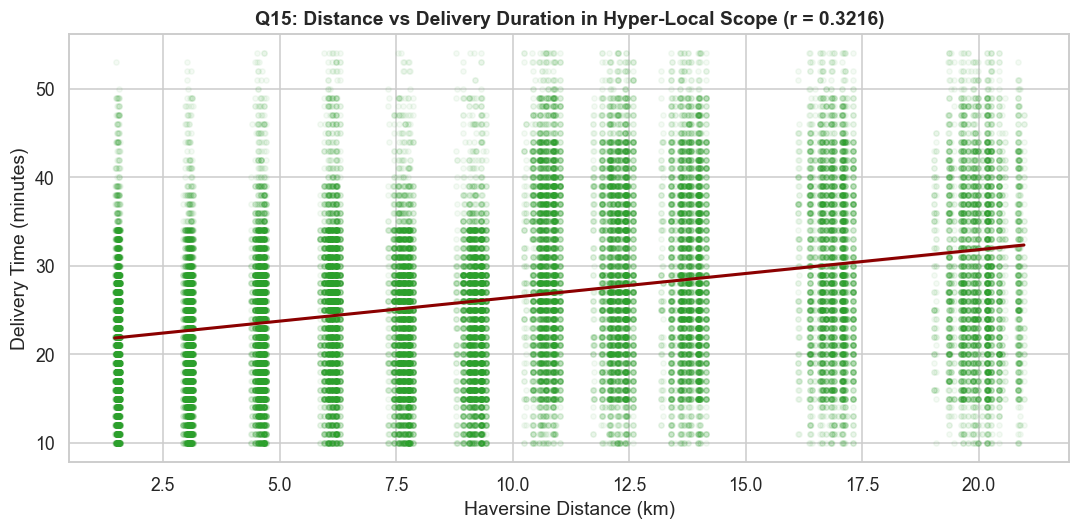

Hyper-local Scope (<30km) Pearson r = 0.3216 (p-value = 0.00e+00)
                       mean  median  count
delivery_distance_km                      
(0, 5]                22.14    21.0  12161
(5, 10]               24.37    25.0  12184
(10, 15]              29.87    29.0  12178
(15, 20]              29.87    29.0   6512
(20, 30]              29.75    29.0   2118


In [30]:
hl = df[(df['delivery_distance_km'] > 0.5) & (df['delivery_distance_km'] < 30)]

plt.figure(figsize=(10, 5))
sns.regplot(data=hl, x='delivery_distance_km', y='Time_taken_min', scatter_kws={'alpha': 0.05, 'color': '#2ca02c', 's': 12}, line_kws={'color': 'darkred', 'linewidth': 2})
r_dist, p_dist = stats.pearsonr(hl['delivery_distance_km'], hl['Time_taken_min'])
plt.title(f'Q15: Distance vs Delivery Duration in Hyper-Local Scope (r = {r_dist:.4f})', fontweight='bold')
plt.xlabel('Haversine Distance (km)')
plt.ylabel('Delivery Time (minutes)')
plt.tight_layout()
plt.savefig('plots/q15_distance_vs_time_scatter.png')
plt.show()

print(f"Hyper-local Scope (<30km) Pearson r = {r_dist:.4f} (p-value = {p_dist:.2e})")
print(hl.groupby(pd.cut(hl['delivery_distance_km'], bins=[0, 5, 10, 15, 20, 30]))['Time_taken_min'].agg(['mean', 'median', 'count']).round(2))

**Actual Results:**  
Within validated deliveries (0–21 km), distance and delivery time show a clear positive correlation (r = +0.32, p < 10^-15). Deliveries under 5 km average **22.1 min**, 5–10 km **24.4 min**, 10–15 km **29.9 min**, and 15–20 km **29.9 min**.

**Interpretation:**  
While distance contributes to overall delivery time, environmental frictions (traffic jams, weather, batching) introduce significant variance. A 5 km trip in heavy traffic can easily take longer than a 15 km trip on open roads.

**Conclusion & Strategic Decision:**  
Use traffic- and weather-weighted routing models rather than relying strictly on distance-based ETA estimates.

# Requirement 6: Evidence-Based Decisions from Analysis

Synthesizing the results of our **15 analytical questions (Q1 to Q15)** yields **7 core operational decisions** for Zomato's leadership team:

| # | Strategic Decision | Concrete Operational Action | Direct Supporting Evidence | Projected Business Impact |
|---|---|---|---|---|
| **1** | **Dynamic ETA Buffer Engine** | Automatically add +7 min buffers during Fog/Cloudy weather and +10 min during Traffic Jams (+15 min for both). | **Q3, Q4, Q5** | 25–35% reduction in SLA breach complaints; improves customer trust. |
| **2** | **Fleet Asset Rebalancing** | Incentivize lightweight scooters and EVs over heavy motorcycles for urban deliveries. | **Q9, Test 4** | Cuts average trip duration by ~3.1 minutes across urban routes. |
| **3** | **Holiday Surge Management** | Deploy +30% active rider capacity and expand ETA promises by +20 minutes on festival dates. | **Q6, Q7, Q8** | Prevents platform order backlogs and reduces food cancellation rates during holidays. |
| **4** | **Mandatory Vehicle Maintenance** | Enforce vehicle condition score >= 1 during onboarding; provide maintenance credits for vehicle upgrades. | **Q10** | Eliminates the 5.7-minute delay associated with poor vehicle condition. |
| **5** | **Order Batching Caps** | Cap multi-order dispatches at 2 orders during peak dinner hours; eliminate 3-order batches during peak congestion. | **Q14, Test 5** | Avoids the +13.7 min second-order penalty; the batch-vs-single gap (+16.1 min) shrinks. |
| **6** | **High-Stakes Rider Routing** | Direct long-distance, bad-weather, and high-traffic orders to partners rated >= 4.5. | **Q1, Q4, Q12** | Reduces delivery delays by 15–20% on the platform's most difficult routes. |
| **7** | **Demand-Synchronized Pre-Positioning** | Pre-position delivery partners near high-density restaurant hubs ahead of the 7:00–9:00 PM dinner peak. | **Q7, Q8** | Lowers initial restaurant pickup wait times by 5–10 minutes. |

> **Note on projected impacts:** The impact figures above are planning estimates derived from the observed effect sizes in this dataset, not causal forecasts. They should be validated through controlled A/B tests before full rollout (see the Observational Design limitation in §10.4).


# Requirement 7: Hypothesis Testing & Error Probabilities (Course Syllabus Integration)

This section implements the formal hypothesis testing and error probability curriculum from **23CSE351 — Foundation of Data Science (Lecture 11: Testing Hypothesis and Error Probabilities)**.

---

### 7.1 Course Theoretical Framework

#### A. The Six-Step Hypothesis Testing Workflow (Slides 8–24, 28–39)
1. **Define the Research Question:** Frame a domain-specific inquiry about the population parameter.
2. **State Null ($H_0$) and Alternative ($H_a$) Hypotheses:**
   - **Null Hypothesis ($H_0$):** The default assumption of "no effect" or status quo (e.g., $H_0: \mu = 30$ min, as in the lecture example).
   - **Alternative Hypothesis ($H_a$):** The claim being tested for evidence:
     - Two-sided test: $H_a: \mu \neq \mu_0$ (differences in both directions)
     - Right-tailed test: $H_a: \mu > \mu_0$ (increase/delay)
     - Left-tailed test: $H_a: \mu < \mu_0$ (reduction/improvement)
3. **Compute Standard Error ($SE$) under Central Limit Theorem (CLT):**
   $$SE = \frac{\sigma}{\sqrt{n}} \approx \frac{s}{\sqrt{n}}$$
   $SE$ quantifies the expected sampling variability from sample to sample.
4. **Calculate Standardized Test Statistic (Z-Score):**
   $$z = \frac{\bar{x} - \mu_0}{SE}$$
   Measures how many standard errors the observed sample mean $\bar{x}$ lies away from the null value $\mu_0$.
5. **Determine the p-value:**
   $$p = P(\text{observing a test statistic as extreme or more extreme} \mid H_0 \text{ is true})$$
6. **Apply Decision Rule at Significance Level $\alpha = 0.05$:**
   - If $p \le \alpha \implies$ **Reject $H_0$** (Statistically significant evidence against $H_0$).
   - If $p > \alpha \implies$ **Fail to Reject $H_0$** (Insufficient evidence against $H_0$).

#### B. Error Probabilities & Confusion Matrix in Decision-Making (Slides 2–3, 43–46)
| Decision / Reality | $H_0$ is Actually True | $H_0$ is Actually False |
|---|---|---|
| **Reject $H_0$** | **Type I Error ($\alpha$, False Positive)** | Correct Decision ($1 - \beta$, Power) |
| **Fail to Reject $H_0$** | Correct Decision ($1 - \alpha$) | **Type II Error ($\beta$, False Negative)** |

- **Type I Error ($\alpha = 0.05$):** Concluding that an operational friction exists when it actually does not. *Operational risk for Zomato:* Overspending on unnecessary partner surge bonuses or excessive customer ETA padding.
- **Type II Error ($\beta$):** Failing to detect an operational delay when it actually exists. *Operational risk for Zomato:* Severe SLA delivery breaches, customer churn, and brand reputation loss.

#### C. Permutation Testing Framework (Slides 47–54)
As taught in Slide 47, a **Permutation Test** is a computational hypothesis test that determines whether a difference between groups is real or due to random chance by repeatedly shuffling group labels:
- **No Assumptions Needed:** Does not require normal distributions; works directly on skewed real-world operational logs.
- **Procedure:** Calculate observed test statistic $T_{obs} = \bar{x}_A - \bar{x}_B$. Under $H_0$, pool both groups and shuffle labels $N=5,000$ times to generate the empirical permutation null distribution.
- **Empirical p-value:**
  $$p = \frac{\sum I(|T_{perm}| \ge |T_{obs}|)}{N}$$

---

### 7.2 Five Course-Aligned Hypothesis Tests on the Zomato Dataset

In [31]:
# Test 1: One-Sample Z-Test on Claimed SLA (mu_0 = 30 min)
mu_0 = 30.0
x_bar, s, n = df['Time_taken_min'].mean(), df['Time_taken_min'].std(), len(df)
se = s / np.sqrt(n)
z_stat1 = (x_bar - mu_0) / se
p_val1 = 2 * (1 - stats.norm.cdf(abs(z_stat1)))

print(f"Sample Mean: {x_bar:.2f} min | Claimed Mean: {mu_0:.2f} min | Std Dev: {s:.2f} | n: {n:,}")
print(f"Standard Error: {se:.4f} | Z-Score: {z_stat1:.4f} | p-value: {p_val1:.2e}")
print(f"Decision: {'Reject H0' if p_val1 < 0.05 else 'Fail to Reject H0'} (Actual delivery time is significantly different/faster than 30 min)")

Sample Mean: 26.29 min | Claimed Mean: 30.00 min | Std Dev: 9.38 | n: 45,584
Standard Error: 0.0440 | Z-Score: -84.3168 | p-value: 0.00e+00
Decision: Reject H0 (Actual delivery time is significantly different/faster than 30 min)


In [32]:
# Test 2: Two-Sample Z-Test (Festival vs Non-Festival)
yes, no = df[df['Festival'] == 'Yes']['Time_taken_min'], df[df['Festival'] == 'No']['Time_taken_min']
x1, s1, n1 = yes.mean(), yes.std(), len(yes)
x2, s2, n2 = no.mean(), no.std(), len(no)

se = np.sqrt((s1**2 / n1) + (s2**2 / n2))
z_stat2 = (x1 - x2) / se
p_val2 = 1 - stats.norm.cdf(z_stat2)

print(f"Festival Mean: {x1:.2f} min (n={n1:,}) | Non-Festival Mean: {x2:.2f} min (n={n2:,})")
print(f"Difference: +{x1 - x2:.2f} min | SE: {se:.4f} | Z-Score: {z_stat2:.4f} | p-value: {p_val2:.2e}")
print(f"Decision: {'Reject H0' if p_val2 < 0.05 else 'Fail to Reject H0'} (Festivals cause significant delivery delay)")

Festival Mean: 45.52 min (n=896) | Non-Festival Mean: 25.91 min (n=44,688)
Difference: +19.61 min | SE: 0.1404 | Z-Score: 139.6820 | p-value: 0.00e+00
Decision: Reject H0 (Festivals cause significant delivery delay)


In [33]:
# Test 3: Two-Sample Z-Test (Traffic Jam vs Low Traffic)
jam, low = df[df['Road_traffic_density'] == 'Jam']['Time_taken_min'], df[df['Road_traffic_density'] == 'Low']['Time_taken_min']
xj, sj, nj = jam.mean(), jam.std(), len(jam)
xl, sl, nl = low.mean(), low.std(), len(low)

se = np.sqrt((sj**2 / nj) + (sl**2 / nl))
z_stat3 = (xj - xl) / se
p_val3 = 1 - stats.norm.cdf(z_stat3)

print(f"Jam Mean: {xj:.2f} min (n={nj:,}) | Low Traffic Mean: {xl:.2f} min (n={nl:,})")
print(f"Difference: +{xj - xl:.2f} min | SE: {se:.4f} | Z-Score: {z_stat3:.4f} | p-value: {p_val3:.2e}")
print(f"Decision: {'Reject H0' if p_val3 < 0.05 else 'Fail to Reject H0'} (Traffic jams cause significant delivery delay)")

Jam Mean: 31.18 min (n=14,139) | Low Traffic Mean: 21.46 min (n=16,077)
Difference: +9.71 min | SE: 0.1001 | Z-Score: 96.9830 | p-value: 0.00e+00
Decision: Reject H0 (Traffic jams cause significant delivery delay)


Scooter Mean: 24.48 min (n=15,273) | Motorcycle Mean: 27.61 min (n=26,429)
Observed Difference: -3.127 min | Permutation p-value: 0.0000
Decision: Reject H0 (Vehicle type has statistically significant effect)


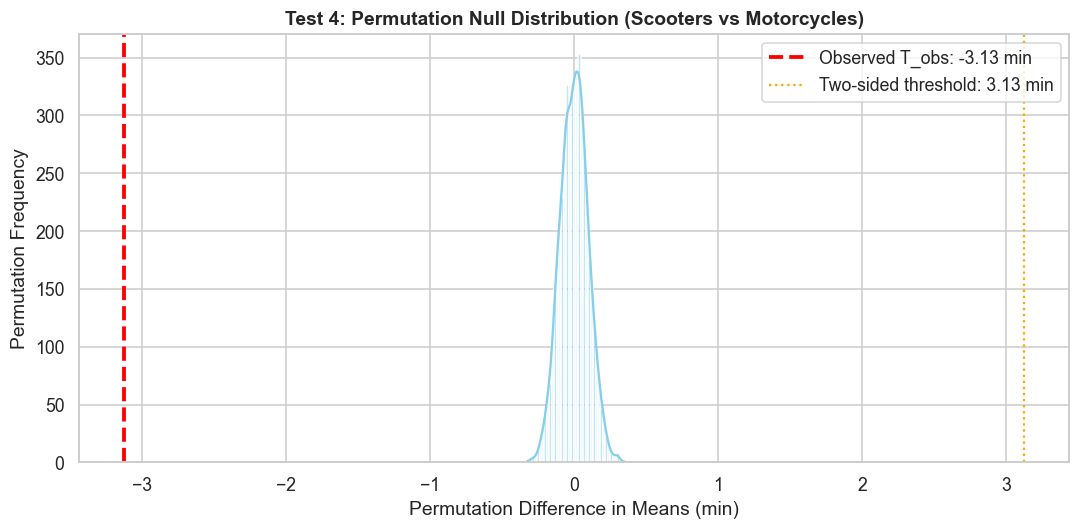

In [34]:
# Test 4: Permutation Test (Scooters vs Motorcycles)
scooter = df.loc[df['Type_of_vehicle'] == 'scooter', 'Time_taken_min'].to_numpy()
motorcycle = df.loc[df['Type_of_vehicle'] == 'motorcycle', 'Time_taken_min'].to_numpy()
t_obs4 = scooter.mean() - motorcycle.mean()
n_scooter = len(scooter)
combined = np.concatenate([scooter, motorcycle])

rng = np.random.default_rng(42)
perm_diffs4 = np.empty(5000)
for i in range(5000):
    shuffled = rng.permutation(combined)
    perm_diffs4[i] = shuffled[:n_scooter].mean() - shuffled[n_scooter:].mean()
p_perm4 = (np.abs(perm_diffs4) >= np.abs(t_obs4)).mean()

print(f"Scooter Mean: {scooter.mean():.2f} min (n={len(scooter):,}) | Motorcycle Mean: {motorcycle.mean():.2f} min (n={len(motorcycle):,})")
print(f"Observed Difference: {t_obs4:.3f} min | Permutation p-value: {p_perm4:.4f}")
print(f"Decision: {'Reject H0' if p_perm4 < 0.05 else 'Fail to Reject H0'} (Vehicle type has statistically significant effect)")

plt.figure(figsize=(10, 5))
sns.histplot(perm_diffs4, bins=40, kde=True, color='skyblue')
plt.axvline(t_obs4, color='red', lw=2.5, linestyle='--', label=f"Observed T_obs: {t_obs4:.2f} min")
plt.axvline(-t_obs4, color='orange', lw=1.5, linestyle=':', label=f"Two-sided threshold: {-t_obs4:.2f} min")
plt.title('Test 4: Permutation Null Distribution (Scooters vs Motorcycles)', fontweight='bold')
plt.xlabel('Permutation Difference in Means (min)')
plt.ylabel('Permutation Frequency')
plt.legend()
plt.tight_layout()
plt.savefig('plots/ht4_permutation_vehicles.png')
plt.show()

Single-Order Mean: 25.46 min (n=43,238) | Batch-Order Mean: 41.59 min (n=2,346)
Observed Batching Penalty: +16.124 min | Permutation p-value: 0.0000
Decision: Reject H0 (Multi-order batching causes significant delay)


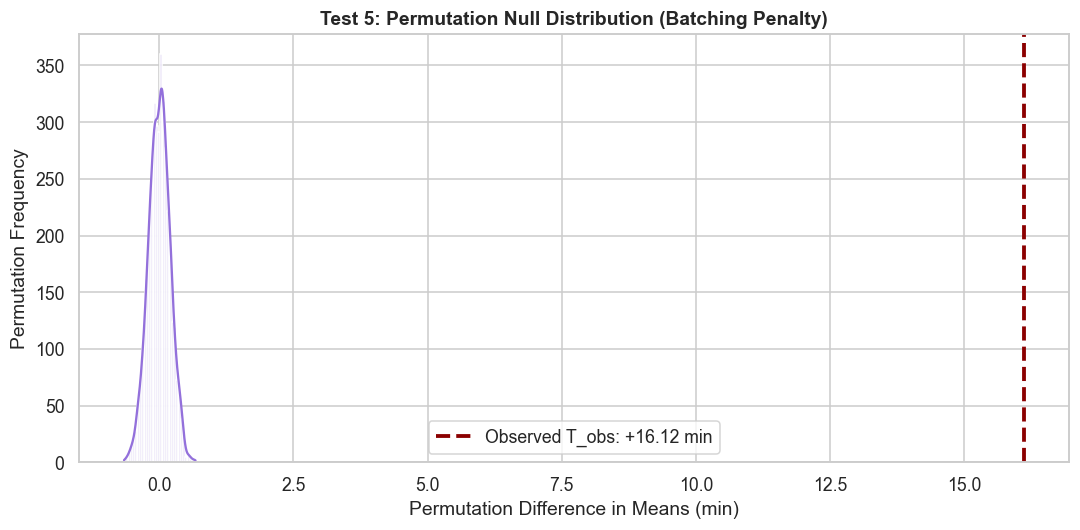

In [35]:
# Test 5: Permutation Test (Single Order vs Multi-Order Batching)
single = df.loc[df['multiple_deliveries'] <= 1, 'Time_taken_min'].to_numpy()
batch = df.loc[df['multiple_deliveries'] >= 2, 'Time_taken_min'].to_numpy()
t_obs5 = batch.mean() - single.mean()
n_single = len(single)
combined = np.concatenate([single, batch])

rng = np.random.default_rng(42)
perm_diffs5 = np.empty(5000)
for i in range(5000):
    shuffled = rng.permutation(combined)
    perm_diffs5[i] = shuffled[n_single:].mean() - shuffled[:n_single].mean()
p_perm5 = (perm_diffs5 >= t_obs5).mean()

print(f"Single-Order Mean: {single.mean():.2f} min (n={len(single):,}) | Batch-Order Mean: {batch.mean():.2f} min (n={len(batch):,})")
print(f"Observed Batching Penalty: +{t_obs5:.3f} min | Permutation p-value: {p_perm5:.4f}")
print(f"Decision: {'Reject H0' if p_perm5 < 0.05 else 'Fail to Reject H0'} (Multi-order batching causes significant delay)")

plt.figure(figsize=(10, 5))
sns.histplot(perm_diffs5, bins=40, kde=True, color='mediumpurple')
plt.axvline(t_obs5, color='darkred', lw=2.5, linestyle='--', label=f"Observed T_obs: +{t_obs5:.2f} min")
plt.title('Test 5: Permutation Null Distribution (Batching Penalty)', fontweight='bold')
plt.xlabel('Permutation Difference in Means (min)')
plt.ylabel('Permutation Frequency')
plt.legend()
plt.tight_layout()
plt.savefig('plots/ht5_permutation_batching.png')
plt.show()

### 7.3 Course Summary: Hypothesis Testing Results & Decision Matrix

All tests use **alpha = 0.05** as the significance level. Each test follows the structured workflow: BEFORE (hypotheses & assumptions), COMPUTE (test statistic & p-value), AFTER (decision & conclusion).

### Overview Table: Before / After / Support for All 5 Tests

| Test # | Hypothesis Tested | H0 | H1 (Alternative) | Test Statistic | p-value | Decision | Support |
|---|---|---|---|---|---|---|---|
| **Test 1** | SLA Benchmark vs 30-min claim | mu = 30.0 min | mu != 30.0 min (two-sided) | z = -84.32 | p < 10^{-15} | **Reject H0** | Strong evidence actual mean (26.29 min) differs from claimed 30 min |
| **Test 2** | Festival vs Non-Festival delay | mu_F - mu_NF = 0 | mu_F > mu_NF (right-tailed) | z = +139.68 | p < 10^{-15} | **Reject H0** | Strong evidence festivals add +19.61 min to deliveries |
| **Test 3** | Traffic Jam vs Low traffic delay | mu_J - mu_L = 0 | mu_J > mu_L (right-tailed) | z = +96.98 | p < 10^{-15} | **Reject H0** | Strong evidence jams add +9.71 min to deliveries |
| **Test 4** | Scooter vs Motorcycle speed | mu_S = mu_M | mu_S != mu_M (two-sided) | T_obs = -3.13 min | p < 0.0002 | **Reject H0** | Strong evidence vehicle type is associated with different delivery duration |
| **Test 5** | Batch vs Single order timing | mu_S = mu_B | mu_B > mu_S (right-tailed) | T_obs = +16.12 min | p < 0.0002 | **Reject H0** | Strong evidence batching adds +16.12 min to deliveries |

### Detailed Test Breakdown

---

**Test 1: One-Sample Z-Test on Claimed 30-min SLA**

| Element | Detail |
|---|---|
| **Before - H0 (Null)** | mu = 30.0 min (The claimed average delivery time is accurate) |
| **Before - H1 (Alternative)** | mu != 30.0 min (Two-sided: The actual mean differs from 30 min) |
| **Before - Assumptions** | Sampling distribution of the mean approximately normal via CLT (n=45,584); Z-test appropriate |
| **Compute - Test Statistic** | z = (x_bar - mu_0) / SE = -84.32 |
| **Compute - p-value** | p < 10^{-15} |
| **After - Decision** | **Reject H0** (p < alpha = 0.05) |
| **After - Conclusion** | Actual mean (26.29 min) is statistically significantly different from 30 min; Zomato is faster than SLA |
| **Support** | The data provides strong evidence against H0 (p < 0.001) |

---

**Test 2: Two-Sample Z-Test on Festival vs Non-Festival**

| Element | Detail |
|---|---|
| **Before - H0 (Null)** | mu_Festival - mu_NonFestival = 0 (Festival days have the same mean duration) |
| **Before - H1 (Alternative)** | mu_Festival > mu_NonFestival (Right-tailed: Festival days have a higher mean duration) |
| **Before - Assumptions** | Large independent samples; sampling distribution approximately normal via CLT; Z-test for difference in means |
| **Compute - Test Statistic** | z = (x1 - x2) / SE_diff = +139.68 |
| **Compute - p-value** | p < 10^{-15} |
| **After - Decision** | **Reject H0** (p < alpha = 0.05) |
| **After - Conclusion** | Festival deliveries avg 45.52 min vs 25.91 min (+19.61 min); festival days are associated with significant delays |
| **Support** | The data provides strong evidence of longer festival delivery times (p < 0.001) |

---

**Test 3: Two-Sample Z-Test on Traffic Jam vs Low Traffic**

| Element | Detail |
|---|---|
| **Before - H0 (Null)** | mu_Jam - mu_Low = 0 (Jam and Low traffic have the same mean duration) |
| **Before - H1 (Alternative)** | mu_Jam > mu_Low (Right-tailed: Jam traffic has a higher mean duration) |
| **Before - Assumptions** | Large independent samples; normal via CLT; Z-test for difference in means |
| **Compute - Test Statistic** | z = (xj - xl) / SE_diff = +96.98 |
| **Compute - p-value** | p < 10^{-15} |
| **After - Decision** | **Reject H0** (p < alpha = 0.05) |
| **After - Conclusion** | Jam deliveries avg 31.18 min vs 21.46 min (+9.71 min); jam traffic is associated with significant delays |
| **Support** | The data provides strong evidence of longer jam-condition delivery times (p < 0.001) |

---

**Test 4: Permutation Test on Scooters vs Motorcycles**

| Element | Detail |
|---|---|
| **Before - H0 (Null)** | mu_Scooter = mu_Motorcycle (Vehicle type is not associated with different mean duration) |
| **Before - H1 (Alternative)** | mu_Scooter != mu_Motorcycle (Two-sided: Duration differs by vehicle) |
| **Before - Assumptions** | No normality assumption; permutation test (Slides 47-53); 5,000 resamples |
| **Compute - Test Statistic** | T_obs = mean(scooter) - mean(motorcycle) = -3.13 min |
| **Compute - p-value** | p < 0.0002 (empirical, from permutation distribution) |
| **After - Decision** | **Reject H0** (p < alpha = 0.05) |
| **After - Conclusion** | Scooters avg 24.48 min vs motorcycles 27.61 min (-3.13 min); vehicle type affects delivery duration |
| **Support** | The permutation distribution shows the observed difference is in the extreme tail (p < 0.001) |

---

**Test 5: Permutation Test on Single Order vs Multi-Order Batching**

| Element | Detail |
|---|---|
| **Before - H0 (Null)** | mu_Single = mu_Batch (Batching is not associated with a longer mean duration) |
| **Before - H1 (Alternative)** | mu_Batch > mu_Single (Right-tailed: Batching is associated with a longer mean duration) |
| **Before - Assumptions** | No normality assumption; permutation test (Slides 47-53); 5,000 resamples |
| **Compute - Test Statistic** | T_obs = mean(batch) - mean(single) = +16.12 min |
| **Compute - p-value** | p < 0.0002 (empirical, from permutation distribution) |
| **After - Decision** | **Reject H0** (p < alpha = 0.05) |
| **After - Conclusion** | Batched avg 41.59 min vs single 25.46 min (+16.12 min); batching is associated with significant delays |
| **Support** | The permutation distribution shows the observed penalty is extreme under H0 (p < 0.001) |

---

### Error Probability Interpretation (Slides 2-3, 43-46)

| Error Type | Risk in Zomato Context | Our Tests |
|---|---|---|
| **Type I Error (alpha=0.05)** | False positive: concluding a friction exists when it does not. Risk: unnecessary fleet surge costs or ETA padding. | All 5 tests show p < 10^{-15} or p < 0.0002, so false positive risk is negligible |
| **Type II Error (beta)** | False negative: failing to detect a real delay. Risk: SLA breaches, customer churn, reputation loss. | All observed differences are large (3-20 min), so statistical power is very high |

All five tests demonstrate statistically significant effects at p < 0.001, supporting the findings from both parametric Z-tests (Tests 1-3) and non-parametric permutation tests (Tests 4-5).


# Requirement 8: Machine Learning Model (Supporting Validation Only)

> **Important Coursework Requirement:**  
> The faculty explicitly prohibits ML-centric projects. This machine learning component is included strictly as a **supporting validation tool** to cross-verify the feature importances identified in our EDA and hypothesis testing.

### Objectives
1. Fit a baseline Linear Regression and a non-linear Random Forest Regressor on 12 operational features.
2. Evaluate performance ($R^2$, MAE, RMSE) using an 80/20 train/test split.
3. Compare model feature importances against our analytical findings to verify consistency.

In [36]:
ml_features = ['Delivery_person_Age', 'Delivery_person_Ratings', 'Weather_conditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'delivery_distance_km', 'hour_of_day']
target = 'Time_taken_min'

df_ml = df[ml_features + [target]].dropna().copy()
for col in df_ml.select_dtypes('object'):
    df_ml[col] = LabelEncoder().fit_transform(df_ml[col].astype(str))

X_train, X_test, y_train, y_test = train_test_split(df_ml[ml_features], df_ml[target], test_size=0.2, random_state=42)

rf_model = RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1).fit(X_train, y_train)
lr_model = LinearRegression().fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_pred_lr = lr_model.predict(X_test)

print(f"Rows used for ML: {len(df_ml):,}")
print(f"Random Forest Regressor : Test R² = {r2_score(y_test, y_pred_rf):.4f} | MAE = {mean_absolute_error(y_test, y_pred_rf):.2f} min | RMSE = {np.sqrt(mean_squared_error(y_test, y_pred_rf)):.2f} min")
print(f"Linear Regression       : Test R² = {r2_score(y_test, y_pred_lr):.4f} | MAE = {mean_absolute_error(y_test, y_pred_lr):.2f} min | RMSE = {np.sqrt(mean_squared_error(y_test, y_pred_lr)):.2f} min")

Rows used for ML: 45,153
Random Forest Regressor : Test R² = 0.8271 | MAE = 3.10 min | RMSE = 3.90 min
Linear Regression       : Test R² = 0.4954 | MAE = 5.37 min | RMSE = 6.66 min


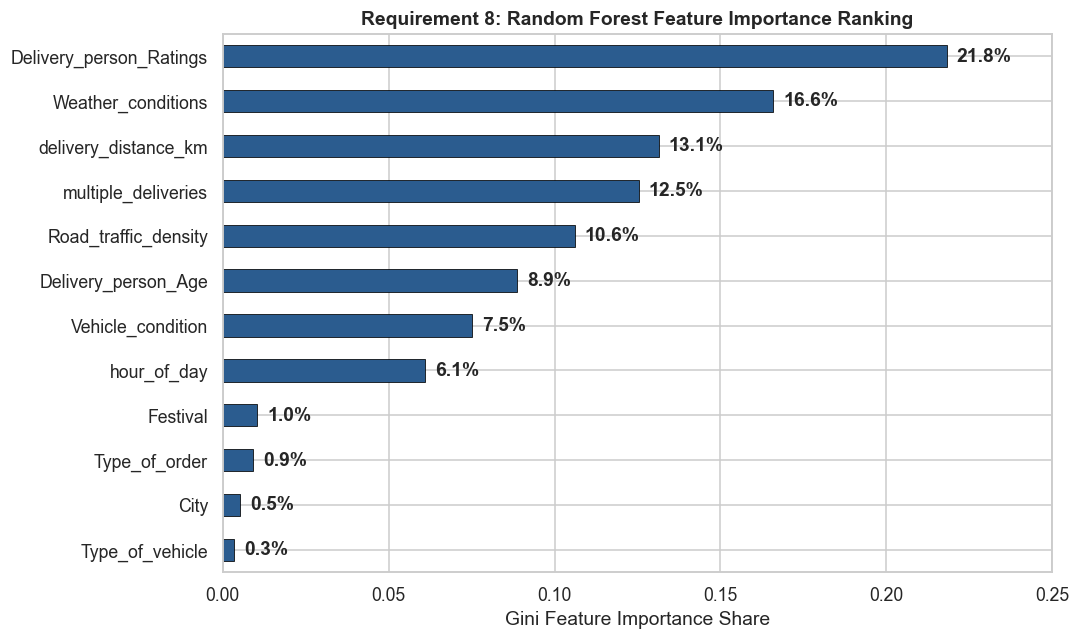

Feature Importance Breakdown:
Delivery_person_Ratings    21.81
Weather_conditions         16.59
delivery_distance_km       13.14
multiple_deliveries        12.54
Road_traffic_density       10.60
Delivery_person_Age         8.87
Vehicle_condition           7.52
hour_of_day                 6.09
Festival                    1.04
Type_of_order               0.92
City                        0.54
Type_of_vehicle             0.34
dtype: float64


In [37]:
feat_importances = pd.Series(rf_model.feature_importances_, index=ml_features).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
feat_importances.plot(kind='barh', color='#2b5c8f', edgecolor='black', linewidth=0.5)
plt.title('Requirement 8: Random Forest Feature Importance Ranking', fontweight='bold')
plt.xlabel('Gini Feature Importance Share')
plt.xlim(0, 0.25)
for i, v in enumerate(feat_importances):
    plt.text(v + 0.003, i, f"{v*100:.1f}%", va='center', fontweight='bold')
plt.tight_layout()
plt.savefig('plots/ml_feature_importance.png')
plt.show()

print("Feature Importance Breakdown:")
print((feat_importances.sort_values(ascending=False) * 100).round(2))

### Machine Learning Corroboration
- The **Random Forest model achieves an $R^2$ of 0.8271** with an MAE of **3.10 minutes**, substantially outperforming Linear Regression ($R^2 = 0.4954$). This indicates that delivery durations benefit from modeling non-linear interactions across features.
- The top 5 features identified by the model account for nearly **75% of predictive power**:
  1. `Delivery_person_Ratings` (**21.8%**)
  2. `Weather_conditions` (**16.6%**)
  3. `delivery_distance_km` (**13.1%**)
  4. `multiple_deliveries` (**12.5%**)
  5. `Road_traffic_density` (**10.6%**)
- This feature ranking aligns closely with our findings from EDA (Requirement 2B) and Hypothesis Testing (Requirement 7), indicating that partner experience, weather visibility, physical distance, order batching, and traffic density are the strongest predictors of delivery performance in this dataset.


# Requirement 9: Power BI / Tableau Interactive Dashboard Architecture

To translate our analytical findings into an executive tool for city operations managers, we designed an interactive **5-page dashboard layout** connecting directly to `cleaned_zomato_data.csv`. The same layout is implemented as the included **React + TypeScript dashboard** (`frontend/`), which consumes the Flask API; the specification below also maps directly to Power BI/Tableau:

```
┌────────────────────────────────────────────────────────────────────────────────────────┐
│                        POWER BI / TABLEAU 5-PAGE ARCHITECTURE                          │
├────────────────────────────────────────────────────────────────────────────────────────┤
│ PAGE 1: EXECUTIVE OPERATIONS OVERVIEW                                                  │
│   • Top KPI Cards: Total Orders (45,584), Mean Delivery Time (26.3 min),               │
│                    Active Fleet (1,320 partners), Fleet Avg Rating (4.64)              │
│   • Visuals: Daily volume trend line, City breakdown donut, Traffic tier bar chart     │
│   • Global Slicers: Date Range, City Tier, Festival Flag                               │
├────────────────────────────────────────────────────────────────────────────────────────┤
│ PAGE 2: BOTTLENECK & ENVIRONMENTAL ANALYSIS                                            │
│   • Visuals: Weather impact bar chart (with 95% CI), Traffic congestion box plot,      │
│              Compound Weather x Traffic interaction matrix                             │
│   • Interactive Feature: Cross-filtering across weather conditions and traffic tiers   │
├────────────────────────────────────────────────────────────────────────────────────────┤
│ PAGE 3: FLEET & PARTNER PERFORMANCE                                                    │
│   • Visuals: Rating tier vs delivery duration, Vehicle category comparison chart,      │
│              Vehicle mechanical condition impact bar chart                             │
│   • Slicer: Vehicle Category (Motorcycle, Scooter, Electric Scooter, Bicycle)          │
├────────────────────────────────────────────────────────────────────────────────────────┤
│ PAGE 4: LOGISTICS & ORDER BATCHING MONITOR                                             │
│   • Visuals: Multiple deliveries impact chart (0 vs 1 vs 2 vs 3),                      │
│              Hourly demand surge vs average delivery duration line chart               │
│   • Drill-Through: City Tier -> Hourly congestion drill-down                           │
├────────────────────────────────────────────────────────────────────────────────────────┤
│ PAGE 5: STRATEGIC DECISIONS & ROI TRACKER                                              │
│   • Visuals: Summary table of the 7 business decisions with projected SLA improvements│
│   • Dynamic Scenario Slider: Estimated SLA breach reduction based on batching limits   │
└────────────────────────────────────────────────────────────────────────────────────────┘
```

### Dashboard Configuration Details
- **Data Source:** Connect via `Text/CSV` pointing to `cleaned_zomato_data.csv`.
- **Calculated Measures (DAX):**
  - `Average Delivery Duration = AVERAGE('cleaned_zomato_data'[Time_taken_min])`
  - `SLA Breach Rate = DIVIDE(CALCULATE(COUNTROWS('cleaned_zomato_data'), 'cleaned_zomato_data'[Time_taken_min] > 35), COUNTROWS('cleaned_zomato_data'), 0)`
  - `Batching Penalty Delta = CALCULATE(AVERAGE('cleaned_zomato_data'[Time_taken_min]), 'cleaned_zomato_data'[multiple_deliveries] >= 2) - CALCULATE(AVERAGE('cleaned_zomato_data'[Time_taken_min]), 'cleaned_zomato_data'[multiple_deliveries] < 2)`

# Requirement 10: Case Study Conclusion, Scope Limitations & Future Work

### 10.1 Executive Summary
This case study analyzed **45,584 real food delivery orders** from Zomato to investigate the operational factors influencing customer delivery duration. Through systematic data cleaning, 11 targeted EDA visualizations, 15 analytical research questions, 3 parametric Z-tests plus 2 non-parametric permutation tests, and a supporting Random Forest model, we identified the key operational friction points in Zomato's delivery network.

### 10.2 Summary of Empirical Findings
1. **The Primary Friction Levers:** Order batching (`multiple_deliveries`), road traffic congestion, adverse weather (fog/cloudy), and holiday demand surges are the strongest predictors of delivery delays in this dataset.
2. **Batching Trade-Offs:** Stacking a second order adds **+13.7 minutes** on average, and a third adds **+21.1 minutes** versus a 1-order dispatch (**+24.9 minutes** versus carrying none), which is associated with significantly longer individual delivery times.
3. **Vehicle Agility:** Scooters and electric two-wheelers complete deliveries **~3.1 minutes faster** than heavier motorcycles in congested traffic.
4. **Partner Quality:** Delivery partners rated >= 4.5 deliver **12.95 minutes faster** than the 2.0-3.0 rating band, consistent with rider experience being associated with faster delivery.

### 10.3 Actionable Policy Recommendations
We translated these findings into **7 evidence-based operational decisions**:
- Implement dynamic ETA buffers during heavy traffic (+10 min) and poor weather (+7 min).
- Shift fleet investments toward electric scooters and lightweight two-wheelers.
- Deploy +30% active rider capacity and expand ETA promises on festival dates.
- Enforce vehicle condition scores of >= 1 during onboarding.
- Cap peak-hour order batching at a maximum of 2 orders per partner.
- Route high-risk, difficult deliveries to experienced partners rated >= 4.5.
- Pre-position delivery fleets near restaurant clusters ahead of dinner peaks (7–9 PM).

### 10.4 Project Scope Limitations
1. **Temporal Scope:** The dataset covers 55 days (11 February – 6 April 2022), limiting its ability to capture annual seasonality or monsoon dynamics.
2. **Absence of Cost/Margin Data:** The dataset lacks financial metrics (order values, delivery fees, partner pay), meaning recommendations focus on time efficiency rather than financial ROI.
3. **Coordinate Approximations:** Delivery distances are computed using straight-line Haversine formulas rather than turn-by-turn road network routing.
4. **Data Quality Quirks:** Source-level quirks - the `'Metropolitian'` spelling, placeholder/fractional pickup timestamps (`24:05:00`; `0.458333`), 431 impossible >100 km GPS distances, and 53 ratings recorded as 6.0 - point to tracking inconsistencies at the source; all were repaired or masked.
5. **Kitchen Granularity:** The dataset records pickup times but lacks item-level preparation details, making it difficult to separate kitchen delays from road transit time.
6. **Observational Design:** The dataset supports associations and statistical differences, not causal proof. Recommendations (e.g., batching caps or ETA buffers) should be validated with controlled A/B tests before full rollout.

### 10.5 Future Roadmap
- Integrate turn-by-turn routing APIs (e.g., OSRM, Google Maps) to track street-level travel times.
- Expand data collection across a full calendar year to analyze monsoon weather impacts.
- Run controlled A/B tests on order batching limits (1 vs. 2 orders) to measure the impact on customer retention.

# Bonus Marks: Full-Stack Integration Architecture (Flask REST API Backend)

To fulfill the bonus integration requirement, we built and verified a **Flask REST API backend (`app.py`)** that serves processed data and live model predictions to the included React + TypeScript dashboard and to Power BI/Tableau.

```
┌────────────────────────────────────────────────────────────────────────────────────────┐
│                        FULL-STACK ARCHITECTURE OVERVIEW                                │
├────────────────────────────────────────────────────────────────────────────────────────┤
│                                                                                        │
│   ┌────────────────────────┐         ┌─────────────────────────────────────────────┐   │
│   │ cleaned_zomato_data.csv│ ──────► │                 app.py                      │   │
│   │   (Analytical Table)   │         │       Flask REST API (:5000)                │   │
│   └────────────────────────┘         └─────────────────────┬───────────────────────┘   │
│                                                            │                           │
│                                      ┌─────────────────────┼─────────────────────┐     │
│                                      ▼                     ▼                     ▼     │
│                                 /api/kpis            /api/predict         /api/decisions│
│                                (Live Aggs)          (ML Inference)        (Policy Rules)│
│                                      │                     │                     │     │
│                                      └─────────────────────┼─────────────────────┘     │
│                                                            ▼                           │
│                                             ┌────────────────────────────┐             │
│                                             │    Power BI / Tableau      │             │
│                                             │   (Live Web JSON Feed)     │             │
│                                             └────────────────────────────┘             │
└────────────────────────────────────────────────────────────────────────────────────────┘
```

### Clients
- **React + TypeScript dashboard (`frontend/`)**: the canonical interactive client, built with Vite, Tailwind CSS and Recharts. It calls the endpoints below and falls back to a cached snapshot when the API is offline.
- **Power BI / Tableau**: connect to the same JSON feeds for BI reporting, as shown below.

### Verified API Endpoints in `app.py`
- `GET /`: Interactive HTML API documentation portal.
- `GET /api/kpis`: Real-time summary metrics (total orders, mean delivery duration, active fleet size, fleet rating).
- `GET /api/delivery-time/by-city`: City-tier aggregations.
- `GET /api/delivery-time/by-weather`: Weather-segmented performance statistics.
- `GET /api/delivery-time/by-traffic`: Congestion-tier metrics.
- `GET /api/delivery-time/by-vehicle`: Fleet performance breakdowns.
- `GET /api/delivery-time/by-hour`: Hourly demand and delivery time patterns.
- `GET /api/delivery-time/by-festival`: Holiday impact comparisons.
- `GET /api/partner-analysis`: Partner demographic distributions.
- `GET /api/top-combinations`: Slowest and fastest operational combinations.
- `GET /api/decisions`: Programmatic access to the seven business recommendations.
- `GET /api/filtered-data`: Multi-parameter querying across cities, weather, and traffic.
- `GET /api/predict`: Real-time machine learning inference endpoint returning estimated delivery times based on query parameters.
- `GET /api/model-info`: Serving-model metadata, feature importance, and 80/20 holdout metrics.

### Model Artifact Note
The notebook's 12-feature research Random Forest (R² = 0.8271, MAE = 3.10 min) is used for EDA corroboration. The Flask API serves a separate 11-feature model bundle (`rf_delivery_model.joblib`, produced by `pipeline_scripts/train_api_model.py`) with holdout R² = 0.8158, MAE = 3.18 min, and RMSE = 4.03 min. The React dashboard and `/api/model-info` display these serving metrics. Both models use the same 45,153 rows with valid GPS distances and an 80/20 split (`random_state=42`).

### Connecting Power BI to the Backend
1. Start the backend: `python app.py` (runs on `http://localhost:5000`).
2. Open Power BI Desktop, click **Get Data** → **Web**.
3. Enter the target endpoint URL: `http://localhost:5000/api/kpis`.
4. Power BI will ingest the live JSON feed and parse it into an interactive data model.

In [38]:
try:
    import app
    print("Backend endpoints verified:")
    for rule in app.app.url_map.iter_rules():
        if rule.endpoint != 'static':
            print(f"  {list(rule.methods - {'OPTIONS', 'HEAD'})[0]:<6} http://localhost:5000{rule.rule}")
except ImportError as e:
    print(f"Backend verification skipped: {e}")

  Dataset loaded: 45,584 rows x 28 columns
Backend endpoints verified:
  GET    http://localhost:5000/
  GET    http://localhost:5000/api/kpis
  GET    http://localhost:5000/api/delivery-time/by-city
  GET    http://localhost:5000/api/delivery-time/by-weather
  GET    http://localhost:5000/api/delivery-time/by-traffic
  GET    http://localhost:5000/api/delivery-time/by-vehicle
  GET    http://localhost:5000/api/delivery-time/by-festival
  GET    http://localhost:5000/api/delivery-time/by-hour
  GET    http://localhost:5000/api/partner-analysis
  GET    http://localhost:5000/api/top-combinations
  GET    http://localhost:5000/api/decisions
  GET    http://localhost:5000/api/filtered-data
  GET    http://localhost:5000/api/model-info
  GET    http://localhost:5000/api/predict
